In [ ]:
#Intelli-speech

In [ ]:
#Github connection check

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/Intelli-Speech-data")

print("Folder exists:", DATASET_DIR.exists())
print("Number of items:", len(list(DATASET_DIR.iterdir())))
print("Sample filenames:")

for file in list(DATASET_DIR.iterdir())[:10]:
    print(file.name)

Folder exists: True
Number of items: 8
Sample filenames:
vaani_telugu_transcribed
openslr_slr66
DEMAND
paired_dataset_v1
paired_dataset_v2
paired_dataset_v3_manifest_speaker_balanced.csv
paired_dataset_v3_pilot
paired_dataset_v3


In [ ]:
from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed"
)

print("Dataset folder exists:", DATASET_DIR.exists())
print("Number of items:", len(list(DATASET_DIR.iterdir())))

Dataset folder exists: True
Number of items: 248


In [ ]:
%cd /content
!git clone https://github.com/niharika9nx/Intelli-Speech.git

/content
Cloning into 'Intelli-Speech'...
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (92/92), done.
remote: Total 121 (delta 29), reused 93 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (121/121), 5.10 MiB | 8.98 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [ ]:
!ls -la /content

total 24
drwxr-xr-x 1 root root 4096 Oct 26 02:34 .
drwxr-xr-x 1 root root 4096 Oct 26 02:25 ..
drwxr-xr-x 4 root root 4096 Oct 21 13:23 .config
drwx------ 5 root root 4096 Oct 26 02:33 drive
drwxr-xr-x 6 root root 4096 Oct 26 02:34 Intelli-Speech
drwxr-xr-x 1 root root 4096 Oct 21 13:23 sample_data


In [ ]:
%cd /content/Intelli-Speech
!git pull origin main

/content/Intelli-Speech
From https://github.com/niharika9nx/Intelli-Speech
 * branch            main       -> FETCH_HEAD
Already up to date.


In [ ]:
%cd /content/Intelli-Speech
!git pull origin main

/content/Intelli-Speech
From https://github.com/niharika9nx/Intelli-Speech
 * branch            main       -> FETCH_HEAD
Already up to date.


In [ ]:
%cd /content/Intelli-Speech
!python scripts/inspect_dataset.py

/content/Intelli-Speech
{
  "dataset_root": "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed",
  "read_only": true,
  "inspection_limits": {
    "audio_sample_size": 100,
    "metadata_file_size_limit_bytes": 20971520,
    "metadata_row_limit": 100000
  },
  "structure": {
    "file_count": 248,
    "directory_count_including_root": 1,
    "empty_directories": [],
    "files_by_directory": {
      ".": 248
    },
    "file_count_by_extension": {
      ".csv": 2,
      ".wav": 246
    },
    "bytes_by_extension": {
      ".csv": 128077,
      ".wav": 49822790
    },
    "zero_byte_file_count": 0
  },
  "audio_candidates": {
    "extension_set": [
      ".aac",
      ".aif",
      ".aiff",
      ".flac",
      ".m4a",
      ".mp3",
      ".oga",
      ".ogg",
      ".opus",
      ".wav",
      ".wma"
    ],
    "candidate_count": 246,
    "empty_candidate_count": 0,
    "sample_inspection": {
      "sampling_method": "evenly spaced from lexicographically sorted audio 

In [ ]:
from pathlib import Path

REPO_DIR = Path("/content/Intelli-Speech")
DATASET_DIR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed"
)

print("Repository exists:", REPO_DIR.exists())
print("Dataset exists:", DATASET_DIR.exists())
print("Metadata exists:", (DATASET_DIR / "metadata.csv").exists())
print("WAV files:", len(list(DATASET_DIR.glob("*.wav"))))

Repository exists: True
Dataset exists: True
Metadata exists: True
WAV files: 246


In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
# Audio files quality check

In [ ]:
!pip -q install soundfile librosa

In [ ]:
from pathlib import Path
import soundfile as sf
import numpy as np
import pandas as pd

DATA_DIR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed"
)

files = sorted(DATA_DIR.glob("*.wav"))[:50]
results = []

for path in files:
    try:
        audio, sr = sf.read(path, dtype="float32")
        if audio.ndim == 2:
            audio = audio.mean(axis=1)

        results.append({
            "filename": path.name,
            "sample_rate": sr,
            "duration_sec": len(audio) / sr,
            "peak_amplitude": float(np.max(np.abs(audio))) if len(audio) else 0,
            "rms_level": float(np.sqrt(np.mean(audio**2))) if len(audio) else 0,
            "silent_fraction": float(np.mean(np.abs(audio) < 0.001)) if len(audio) else 1,
            "valid": len(audio) > 0
        })

    except Exception as e:
        results.append({
            "filename": path.name,
            "valid": False,
            "error": str(e)
        })

audit = pd.DataFrame(results)
display(audit)
print("\nFiles inspected:", len(files))
print("Readable files:", int(audit["valid"].fillna(False).sum()))

,filename,sample_rate,duration_sec,peak_amplitude,rms_level,silent_fraction,valid
0,telugu_0001.wav,16000,9.634000,0.999969,0.138260,0.015648,True
1,telugu_0002.wav,16000,11.829000,1.000000,0.105692,0.017684,True
2,telugu_0003.wav,16000,3.864000,0.999969,0.120587,0.016110,True
3,telugu_0004.wav,16000,9.355000,0.999969,0.103208,0.037440,True
4,telugu_0005.wav,16000,6.034000,0.878906,0.112942,0.013269,True
5,telugu_0006.wav,16000,9.845000,0.576508,0.075569,0.017426,True
6,telugu_0007.wav,16000,6.834000,1.000000,0.114136,0.017806,True
7,telugu_0008.wav,16000,7.718000,0.314148,0.027218,0.136402,True
8,telugu_0009.wav,16000,9.418000,0.086853,0.012650,0.231896,True
9,telugu_0010.wav,16000,7.435000,0.142609,0.022344,0.094385,True



Files inspected: 50
Readable files: 50


In [ ]:
from IPython.display import Audio, display
from pathlib import Path
import soundfile as sf

folder = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed"
)

for name in [
    "telugu_0001.wav",
    "telugu_0009.wav",
    "telugu_0018.wav",
    "telugu_0030.wav",
    "telugu_0040.wav",
]:
    path = folder / name
    audio, sr = sf.read(path, dtype="float32")

    print(name, f"({len(audio)/sr:.1f} seconds)")
    display(Audio(audio, rate=sr))

telugu_0001.wav (9.6 seconds)


telugu_0009.wav (9.4 seconds)


telugu_0018.wav (14.5 seconds)


telugu_0030.wav (6.8 seconds)


telugu_0040.wav (6.4 seconds)


In [ ]:

from pathlib import Path
import numpy as np
import soundfile as sf
from IPython.display import Audio, display

folder = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed"
)

files = sorted(folder.glob("*.wav"))

if len(files) < 20:
    raise ValueError(f"Only {len(files)} WAV files found.")

# Select 20 clips spread across the dataset
indices = np.linspace(0, len(files) - 1, 20, dtype=int)
selected_files = [files[i] for i in indices]

print(f"Examining {len(selected_files)} clips\n")

for i, path in enumerate(selected_files, 1):
    try:
        audio, sr = sf.read(path, dtype="float32")
        if audio.ndim == 2:
            audio = audio.mean(axis=1)

        duration = len(audio) / sr
        peak = float(np.max(np.abs(audio))) if len(audio) else 0.0
        rms = float(np.sqrt(np.mean(audio ** 2))) if len(audio) else 0.0
        clipped = float(np.mean(np.abs(audio) >= 0.999))

        print(
            f"{i:02}. {path.name} | "
            f"{duration:.2f}s | {sr} Hz | "
            f"RMS={rms:.4f} | Peak={peak:.4f} | "
            f"Near-clipped={clipped:.2%}"
        )
        display(Audio(audio, rate=sr))

    except Exception as e:
        print(f"{i:02}. {path.name} | ERROR: {e}")


Examining 20 clips

01. telugu_0001.wav | 9.63s | 16000 Hz | RMS=0.1383 | Peak=1.0000 | Near-clipped=0.00%


02. telugu_0013.wav | 3.38s | 16000 Hz | RMS=0.1853 | Peak=1.0000 | Near-clipped=0.00%


03. telugu_0026.wav | 3.05s | 16000 Hz | RMS=0.1348 | Peak=1.0000 | Near-clipped=0.00%


04. telugu_0039.wav | 2.94s | 16000 Hz | RMS=0.1349 | Peak=0.8723 | Near-clipped=0.00%


05. telugu_0052.wav | 2.97s | 16000 Hz | RMS=0.1725 | Peak=0.7118 | Near-clipped=0.00%


...

16. telugu_0194.wav | 8.55s | 16000 Hz | RMS=0.1575 | Peak=0.8626 | Near-clipped=0.00%


17. telugu_0207.wav | 10.24s | 16000 Hz | RMS=0.0792 | Peak=0.6877 | Near-clipped=0.00%


18. telugu_0220.wav | 11.90s | 16000 Hz | RMS=0.1025 | Peak=1.0000 | Near-clipped=0.00%


19. telugu_0233.wav | 2.86s | 16000 Hz | RMS=0.1643 | Peak=0.7985 | Near-clipped=0.00%


20. telugu_0246.wav | 12.56s | 16000 Hz | RMS=0.0672 | Peak=0.6005 | Near-clipped=0.00%


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf

folder = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/vaani_telugu_transcribed"
)
report_path = folder / "quality_audit_report.csv"

files = sorted(folder.glob("*.wav"))
if not files:
    raise FileNotFoundError(f"No WAV files found in {folder}")

results = []

for i, path in enumerate(files, 1):
    try:
        info = sf.info(str(path))
        audio, sr = sf.read(path, dtype="float32", always_2d=True)
        audio = audio.mean(axis=1)

        if len(audio) == 0:
            raise ValueError("Empty audio")

        abs_audio = np.abs(audio)
        peak = float(abs_audio.max())
        rms = float(np.sqrt(np.mean(audio ** 2)))
        silence_pct = float(np.mean(abs_audio < 0.001) * 100)
        clipping_pct = float(np.mean(abs_audio >= 0.999) * 100)

        results.append({
            "filename": path.name,
            "status": "OK",
            "duration_sec": round(len(audio) / sr, 3),
            "sample_rate": sr,
            "channels": info.channels,
            "file_size_MB": round(path.stat().st_size / 1e6, 3),
            "rms": round(rms, 6),
            "peak": round(peak, 6),
            "near_silence_pct": round(silence_pct, 2),
            "near_clipping_pct": round(clipping_pct, 4),
            "error": ""
        })

    except Exception as e:
        results.append({
            "filename": path.name,
            "status": "ERROR",
            "error": str(e)
        })

    if i % 25 == 0 or i == len(files):
        print(f"Checked {i}/{len(files)} files")

df = pd.DataFrame(results)
df.to_csv(report_path, index=False)

good = df[df["status"] == "OK"]
print("\n--- AUDIT SUMMARY ---")
print(f"Total WAV files: {len(files)}")
print(f"Successfully read: {len(good)}")
print(f"Read errors: {(df['status'] != 'OK').sum()}")

if not good.empty:
    print(f"Duration range: {good['duration_sec'].min():.2f}–"
          f"{good['duration_sec'].max():.2f} seconds")
    print(f"Sample rates: {sorted(good['sample_rate'].unique())}")
    print(f"Total audio: {good['file_size_MB'].sum()/1000:.3f} GB")
    print("\nDuration and signal statistics:")
    print(good[[
        "duration_sec", "rms", "peak",
        "near_silence_pct", "near_clipping_pct"
    ]].describe().round(3))

print(f"\nReport saved to: {report_path}")
display(df.head(10))


Checked 25/246 files
Checked 50/246 files
Checked 75/246 files
Checked 100/246 files
Checked 125/246 files
Checked 150/246 files
Checked 175/246 files
Checked 200/246 files
Checked 225/246 files
Checked 246/246 files

--- AUDIT SUMMARY ---
Total WAV files: 246
Successfully read: 246
Read errors: 0
Duration range: 2.02–14.77 seconds
Sample rates: [np.int64(16000)]
Total audio: 0.050 GB

Duration and signal statistics:
       duration_sec      rms     peak  near_silence_pct  near_clipping_pct
count       246.000  246.000  246.000           246.000            246.000
mean          6.328    0.126    0.803             7.555              0.000
std           3.189    0.055    0.222             6.678              0.001
min           2.020    0.009    0.065             0.570              0.000
25%           3.640    0.091    0.711             2.360              0.000
50%           5.579    0.125    0.836             5.025              0.000
75%           8.116    0.151    1.000            10.63

,filename,status,duration_sec,sample_rate,channels,file_size_MB,rms,peak,near_silence_pct,near_clipping_pct,error
0,telugu_0001.wav,OK,9.634,16000,1,0.308,0.138260,0.999969,1.56,0.0006,
1,telugu_0002.wav,OK,11.829,16000,1,0.379,0.105692,1.000000,1.77,0.0005,
2,telugu_0003.wav,OK,3.864,16000,1,0.124,0.120587,0.999969,1.61,0.0016,
3,telugu_0004.wav,OK,9.355,16000,1,0.299,0.103208,0.999969,3.74,0.0007,
4,telugu_0005.wav,OK,6.034,16000,1,0.193,0.112942,0.878906,1.33,0.0000,
5,telugu_0006.wav,OK,9.845,16000,1,0.315,0.075569,0.576508,1.74,0.0000,
6,telugu_0007.wav,OK,6.834,16000,1,0.219,0.114136,1.000000,1.78,0.0009,
7,telugu_0008.wav,OK,7.718,16000,1,0.247,0.027218,0.314148,13.64,0.0000,
8,telugu_0009.wav,OK,9.418,16000,1,0.301,0.012650,0.086853,23.19,0.0000,
9,telugu_0010.wav,OK,7.435,16000,1,0.238,0.022344,0.142609,9.44,0.0000,


In [ ]:
#Downloading clear audio file from OpenSLR

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import subprocess

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")
base.mkdir(parents=True, exist_ok=True)

files = [
    "te_in_female.zip",
    "te_in_male.zip",
    "line_index_female.tsv",
    "line_index_male.tsv",
]

url_base = "https://www.openslr.org/resources/66/"

for filename in files:
    destination = base / filename

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already downloaded, skipping: {filename}")
        continue

    print(f"\nDownloading {filename}...")
    result = subprocess.run([
        "wget", "-c", "--show-progress",
        "-O", str(destination),
        url_base + filename
    ])

    if result.returncode != 0:
        print(f"Download interrupted or failed: {filename}")
        print("Rerun this cell to resume.")
        break

    print(f"Finished: {filename} ({destination.stat().st_size / 1e6:.1f} MB)")

print("\nDataset folder:", base)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already downloaded, skipping: te_in_female.zip
Already downloaded, skipping: te_in_male.zip
Already downloaded, skipping: line_index_female.tsv
Already downloaded, skipping: line_index_male.tsv

Dataset folder: /content/drive/MyDrive/Intelli-Speech-data/openslr_slr66


In [ ]:
#Testing our downloaded files

In [ ]:
from pathlib import Path
import zipfile

folder = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66"
)

for file in sorted(folder.iterdir()):
    print(f"\n{file.name} — {file.stat().st_size / 1e6:.2f} MB")

    if file.suffix == ".zip":
        with zipfile.ZipFile(file) as z:
            bad_file = z.testzip()
            print("ZIP integrity:", "OK" if bad_file is None else f"Error: {bad_file}")
            print("Files inside:", len(z.namelist()))
            print("Examples:", z.namelist()[:3])


line_index_female.tsv — 0.27 MB

line_index_male.tsv — 0.27 MB

te_in_female.zip — 505.68 MB
ZIP integrity: OK
Files inside: 2296
Examples: ['line_index.tsv', 'tef_01033_00007107192.wav', 'tef_01033_00010179612.wav']

te_in_male.zip — 529.45 MB
ZIP integrity: OK
Files inside: 2156
Examples: ['line_index.tsv', 'tem_00113_00047277637.wav', 'tem_00113_00148830615.wav']


In [ ]:
# Downloading noise audio files

In [ ]:
from pathlib import Path
import subprocess

base = Path("/content/drive/MyDrive/Intelli-Speech-data/DEMAND")
base.mkdir(parents=True, exist_ok=True)

environments = [
    "STRAFFIC",
    "TBUS",
    "NPARK",
    "DKITCHEN",
    "OOFFICE",
]

url_base = "https://zenodo.org/records/1227121/files/"

for env in environments:
    filename = f"{env}_16k.zip"
    destination = base / filename

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue

    print(f"\nDownloading {filename}...")
    result = subprocess.run([
        "wget", "-c", "--show-progress",
        "-O", str(destination),
        url_base + filename + "?download=1"
    ])

    if result.returncode != 0:
        print(f"Download failed or interrupted: {filename}")
        print("Rerun this cell to resume.")
        break

    print(f"Downloaded: {destination.stat().st_size / 1e6:.1f} MB")

print("\nDEMAND folder:", base)

Already downloaded: STRAFFIC_16k.zip
Already downloaded: TBUS_16k.zip
Already downloaded: NPARK_16k.zip
Already downloaded: DKITCHEN_16k.zip
Already downloaded: OOFFICE_16k.zip

DEMAND folder: /content/drive/MyDrive/Intelli-Speech-data/DEMAND


In [ ]:

from pathlib import Path
import zipfile

folder = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/DEMAND"
)

if not folder.exists():
    print("DEMAND folder not found. Check the Drive path.")
else:
    archives = sorted(folder.glob("*.zip"))

    if not archives:
        print("No ZIP files found. Check whether the downloads completed.")

    for file in archives:
        print(f"\n{'=' * 45}")
        print(f"Archive: {file.name}")
        print(f"Size: {file.stat().st_size / 1e6:.2f} MB")

        try:
            with zipfile.ZipFile(file) as z:
                bad_file = z.testzip()
                print(
                    "Integrity:",
                    "OK" if bad_file is None else f"FAILED: {bad_file}"
                )
                print("Files inside:", len(z.namelist()))
                print("Examples:", z.namelist()[:5])
        except zipfile.BadZipFile:
            print("Invalid ZIP file — download may be incomplete.")



Archive: DKITCHEN_16k.zip
Size: 110.50 MB
Integrity: OK
Files inside: 17
Examples: ['DKITCHEN/', 'DKITCHEN/ch08.wav', 'DKITCHEN/ch07.wav', 'DKITCHEN/ch05.wav', 'DKITCHEN/ch14.wav']

Archive: NPARK_16k.zip
Size: 86.03 MB
Integrity: OK
Files inside: 17
Examples: ['NPARK/', 'NPARK/ch08.wav', 'NPARK/ch07.wav', 'NPARK/ch05.wav', 'NPARK/ch14.wav']

Archive: OOFFICE_16k.zip
Size: 89.00 MB
Integrity: OK
Files inside: 17
Examples: ['OOFFICE/', 'OOFFICE/ch08.wav', 'OOFFICE/ch07.wav', 'OOFFICE/ch05.wav', 'OOFFICE/ch14.wav']

Archive: STRAFFIC_16k.zip
Size: 118.57 MB
Integrity: OK
Files inside: 17
Examples: ['STRAFFIC/', 'STRAFFIC/ch08.wav', 'STRAFFIC/ch07.wav', 'STRAFFIC/ch05.wav', 'STRAFFIC/ch14.wav']

Archive: TBUS_16k.zip
Size: 128.92 MB
Integrity: OK
Files inside: 17
Examples: ['TBUS/', 'TBUS/ch08.wav', 'TBUS/ch07.wav', 'TBUS/ch05.wav', 'TBUS/ch14.wav']


In [ ]:

from pathlib import Path
import zipfile

base = Path("/content/drive/MyDrive/Intelli-Speech-data/DEMAND")
extract_to = base / "extracted"
extract_to.mkdir(parents=True, exist_ok=True)

for archive in sorted(base.glob("*_16k.zip")):
    with zipfile.ZipFile(archive, "r") as z:
        bad_file = z.testzip()
        if bad_file is not None:
            print(f"Skipping corrupted archive: {archive.name}")
            continue

        # Keep extraction inside the intended folder.
        safe_members = []
        for name in z.namelist():
            target = (extract_to / name).resolve()
            if target.is_relative_to(extract_to.resolve()):
                safe_members.append(name)
            else:
                raise ValueError(f"Unsafe archive path: {name}")

        z.extractall(extract_to, members=safe_members)

    print(f"Extracted: {archive.name}")

print("\nExtraction folder:", extract_to)


Extracted: DKITCHEN_16k.zip
Extracted: NPARK_16k.zip
Extracted: OOFFICE_16k.zip
Extracted: STRAFFIC_16k.zip
Extracted: TBUS_16k.zip

Extraction folder: /content/drive/MyDrive/Intelli-Speech-data/DEMAND/extracted


In [ ]:

from pathlib import Path
import soundfile as sf

base = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/DEMAND/extracted"
)

for wav in sorted(base.rglob("*.wav")):
    info = sf.info(str(wav))
    print(
        f"{wav.parent.name}/{wav.name}: "
        f"{info.samplerate} Hz, "
        f"{info.channels} channel(s), "
        f"{info.duration:.1f} sec"
    )


DKITCHEN/ch01.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch02.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch03.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch04.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch05.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch06.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch07.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch08.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch09.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch10.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch11.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch12.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch13.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch14.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch15.wav: 16000 Hz, 1 channel(s), 300.0 sec
DKITCHEN/ch16.wav: 16000 Hz, 1 channel(s), 300.0 sec
NPARK/ch01.wav: 16000 Hz, 1 channel(s), 300.0 sec
NPARK/ch02.wav: 16000 Hz, 1 channel(s), 300.0 sec
NPARK/ch03.wav: 16000 Hz, 1 channel(s), 300.0 sec
NP

In [ ]:
# CREATING OUR OWN DATASET - MIXING CLEAR AUDIO WITH NOISE

In [ ]:
# Inspecting the audio archives of openSLR

In [ ]:

from pathlib import Path
import zipfile

base = Path("/content/drive/MyDrive/Intelli-Speech-data")
speech_dir = base / "openslr_slr66"

for name in ["te_in_female.zip", "te_in_male.zip"]:
    path = speech_dir / name

    if not path.exists():
        print(f"MISSING: {path}")
        continue

    with zipfile.ZipFile(path) as z:
        wavs = [f for f in z.namelist()
                if f.lower().endswith(".wav")]

        print(f"\n{name}")
        print(f"Archive valid: {z.testzip() is None}")
        print(f"WAV recordings: {len(wavs)}")
        print("Example files:", wavs[:3])

for name in ["line_index_female.tsv", "line_index_male.tsv"]:
    path = speech_dir / name
    print(f"\n{name}: {'FOUND' if path.exists() else 'MISSING'}")
    if path.exists():
        with path.open(encoding="utf-8") as f:
            for _ in range(3):
                line = f.readline()
                if not line:
                    break
                print(repr(line.rstrip()))



te_in_female.zip
Archive valid: True
WAV recordings: 2294
Example files: ['tef_01033_00007107192.wav', 'tef_01033_00010179612.wav', 'tef_01033_00027597881.wav']

te_in_male.zip
Archive valid: True
WAV recordings: 2154
Example files: ['tem_00113_00047277637.wav', 'tem_00113_00148830615.wav', 'tem_00113_00294763463.wav']

line_index_female.tsv: FOUND
'tef_01033_00351357063\tఈ వివాదం సెప్టెంబర్ రెండు వేల తొమ్మిదిన పరిష్కారమైనది'
'tef_02828_01625402654\tఒక బ్యాంకు ఒక ప్రాథమిక పాఠశాల ఉన్నాయి'
'tef_08318_01333265498\tచాలా గొంగళి పురుగులు షాకాహారులే'

line_index_male.tsv: FOUND
'tem_07220_01981175708\tదీనిని తటస్థీకరణము అందురు'
'tem_06359_01516502961\tదీనిని స్కోరుగా అనువదిస్తారు'
'tem_02812_01868000938\tరెండంతస్తుల భవనాలు పూర్తిగా నీట మునిగాయి'


In [ ]:
# Inspecting audio file quality and transcript matching

In [ ]:

from pathlib import Path
import zipfile
import random
import soundfile as sf
import io

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")

random.seed(42)

for gender, zip_name, index_name in [
    ("female", "te_in_female.zip", "line_index_female.tsv"),
    ("male", "te_in_male.zip", "line_index_male.tsv"),
]:
    print(f"\n--- {gender.upper()} SPEECH ---")

    # Read filename-to-transcript mapping
    transcripts = {}
    with open(base / index_name, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 1)
            if len(parts) == 2:
                transcripts[parts[0]] = parts[1]

    with zipfile.ZipFile(base / zip_name) as z:
        wav_files = [n for n in z.namelist()
                     if n.lower().endswith(".wav")]
        samples = random.sample(wav_files, min(3, len(wav_files)))

        for filename in samples:
            # Filename without .wav should match the transcript index
            key = Path(filename).stem
            transcript = transcripts.get(key)

            audio_bytes = z.read(filename)
            audio, sr = sf.read(io.BytesIO(audio_bytes))

            duration = len(audio) / sr
            print(f"\nFile: {key}")
            print(f"Transcript found: {transcript is not None}")
            print(f"Transcript: {transcript}")
            print(f"Sample rate: {sr} Hz")
            print(f"Duration: {duration:.2f} sec")
            print(f"Channels: {1 if audio.ndim == 1 else audio.shape[1]}")



--- FEMALE SPEECH ---

File: tef_04213_00328970336
Transcript found: True
Transcript: ఎన్నో సినిమాలకు పాటలు మాటలు రాసాడు
Sample rate: 48000 Hz
Duration: 5.21 sec
Channels: 1

File: tef_01908_00506787833
Transcript found: True
Transcript: హదోతి భూభాగంలో ఇది ప్రముఖ్యత కలిగిన నది
Sample rate: 48000 Hz
Duration: 5.03 sec
Channels: 1

File: tef_05705_01414941382
Transcript found: True
Transcript: దీన్ని కూడా దయచేసి వికీలో పెట్టండి
Sample rate: 48000 Hz
Duration: 4.27 sec
Channels: 1

--- MALE SPEECH ---

File: tem_04272_01871239590
Transcript found: True
Transcript: ఈ గ్రామం సముద్ర తీరానికి ఛాలా దగ్గరగా ఉన్నది
Sample rate: 48000 Hz
Duration: 3.75 sec
Channels: 1

File: tem_04272_00885621501
Transcript found: True
Transcript: ఈ గ్రామానికి రైలు సౌకర్యము కూడా ఉంది
Sample rate: 48000 Hz
Duration: 6.91 sec
Channels: 1

File: tem_02812_01379983363
Transcript found: True
Transcript: మళ్ళీ పరిశీలించి మీ అభిప్రాయం వ్రాయండి
Sample rate: 48000 Hz
Duration: 3.58 sec
Channels: 1


In [ ]:
# Check whether the speech is clean enough

In [ ]:

from IPython.display import Audio, display
from pathlib import Path
import zipfile
import io
import soundfile as sf
import numpy as np

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")

samples = [
    ("te_in_female.zip", "tef_04213_00328970336"),
    ("te_in_female.zip", "tef_01908_00506787833"),
    ("te_in_male.zip", "tem_04272_01871239590"),
]

for zip_name, stem in samples:
    with zipfile.ZipFile(base / zip_name) as z:
        with z.open(stem + ".wav") as f:
            audio, sr = sf.read(io.BytesIO(f.read()))

    peak = np.max(np.abs(audio))
    rms = np.sqrt(np.mean(audio ** 2))

    print(f"\n{stem}")
    print(f"Peak amplitude: {peak:.4f}")
    print(f"RMS amplitude: {rms:.4f}")
    display(Audio(audio, rate=sr))




tef_04213_00328970336
Peak amplitude: 0.1083
RMS amplitude: 0.0191



tef_01908_00506787833
Peak amplitude: 0.1605
RMS amplitude: 0.0223



tem_04272_01871239590
Peak amplitude: 0.8770
RMS amplitude: 0.1263


In [ ]:
# Trimming silence audio

In [ ]:

import zipfile
import io
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path
from IPython.display import Audio, display

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")
zip_path = base / "te_in_female.zip"
filename = "tef_04213_00328970336.wav"

with zipfile.ZipFile(zip_path) as z:
    audio, sr = sf.read(io.BytesIO(z.read(filename)))

# Measure speech activity in short frames
intervals = librosa.effects.split(
    audio.astype(np.float32),
    top_db=30,
    frame_length=2048,
    hop_length=512
)

if len(intervals):
    start = intervals[0][0]
    end = intervals[-1][1]
    trimmed = audio[start:end]

    print(f"Original duration: {len(audio)/sr:.2f} sec")
    print(f"Trimmed duration:  {len(trimmed)/sr:.2f} sec")
    print(f"Removed duration:  {(len(audio)-len(trimmed))/sr:.2f} sec")

    print("\nOriginal audio:")
    display(Audio(audio, rate=sr))

    print("\nTrimmed audio:")
    display(Audio(trimmed, rate=sr))
else:
    print("No audio activity detected. Try a different threshold.")


Original duration: 5.21 sec
Trimmed duration:  2.40 sec
Removed duration:  2.81 sec

Original audio:



Trimmed audio:


In [ ]:
# Examining more audio files (trimmed)

In [ ]:

import zipfile
import io
import random
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path
from IPython.display import Audio, display

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")
random.seed(42)

# Sample 10 female and 10 male recordings
archives = [
    ("Female", base / "te_in_female.zip", "line_index_female.tsv"),
    ("Male", base / "te_in_male.zip", "line_index_male.tsv"),
]

for gender, zip_path, index_name in archives:
    print(f"\n{'='*15} {gender.upper()} RECORDINGS {'='*15}")

    index_path = base / index_name
    transcripts = {}

    with open(index_path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 1)
            if len(parts) == 2:
                transcripts[parts[0]] = parts[1]

    with zipfile.ZipFile(zip_path) as z:
        wav_files = [n for n in z.namelist()
                     if n.lower().endswith(".wav")]
        chosen = random.sample(wav_files, 10)

        for i, filename in enumerate(chosen, 1):
            stem = Path(filename).stem

            with z.open(filename) as f:
                audio, sr = sf.read(io.BytesIO(f.read()))

            audio = audio.astype(np.float32)

            # Detect active regions; retain pauses inside the clip
            intervals = librosa.effects.split(
                audio, top_db=30,
                frame_length=2048, hop_length=512
            )

            if len(intervals):
                start, end = intervals[0][0], intervals[-1][1]
                trimmed = audio[start:end]
                removed = len(audio) - len(trimmed)
            else:
                trimmed = audio
                removed = 0

            print(f"\n{gender} {i}/10 — {stem}")
            print(f"Transcript: {transcripts.get(stem, 'NOT FOUND')}")
            print(f"Original: {len(audio)/sr:.2f}s | "
                  f"Trimmed: {len(trimmed)/sr:.2f}s | "
                  f"Removed: {removed/sr:.2f}s")

            print("Trimmed playback:")
            display(Audio(trimmed, rate=sr))



=============== FEMALE RECORDINGS ===============

Female 1/10 — tef_04213_00328970336
Transcript: ఎన్నో సినిమాలకు పాటలు మాటలు రాసాడు
Original: 5.21s | Trimmed: 2.40s | Removed: 2.81s
Trimmed playback:



Female 2/10 — tef_01908_00506787833
Transcript: హదోతి భూభాగంలో ఇది ప్రముఖ్యత కలిగిన నది
Original: 5.03s | Trimmed: 2.74s | Removed: 2.29s
Trimmed playback:



Female 3/10 — tef_05705_01414941382
Transcript: దీన్ని కూడా దయచేసి వికీలో పెట్టండి
Original: 4.27s | Trimmed: 2.19s | Removed: 2.08s
Trimmed playback:



Female 4/10 — tef_05691_01257511244
Transcript: ఈ నేపథ్యంలో వెయ్యి ఏడు వందలు నలభై తొమ్మిదిలో షాహూజీ మరణించాడు
Original: 6.14s | Trimmed: 4.58s | Removed: 1.57s
Trimmed playback:



Female 5/10 — tef_05691_00242581554
Transcript: భేదనాశినీ  భేదములను పోగొట్టునది
Original: 8.79s | Trimmed: 2.73s | Removed: 6.06s
Trimmed playback:


...


Male 6/10 — tem_09222_01922568014
Transcript: ఈ ఆలయం చిన్న తిరుపతి దేవస్థానం వారి నిర్వహణలో ఉంది.
Original: 4.78s | Trimmed: 3.20s | Removed: 1.58s
Trimmed playback:



Male 7/10 — tem_00682_00914815687
Transcript: భాష మాత్రం సమకాలీనంగా మార్చబడింది
Original: 8.45s | Trimmed: 4.15s | Removed: 4.30s
Trimmed playback:



Male 8/10 — tem_03338_01805433698
Transcript: అందుకే అవి రసజ్ఞుల ప్రశంసలు పొందాయి
Original: 3.41s | Trimmed: 2.91s | Removed: 0.50s
Trimmed playback:



Male 9/10 — tem_08680_00775878477
Transcript: తరచు రాజమండ్రి నుండిబస్సు సౌకర్యం ఉన్నది\n
Original: 3.41s | Trimmed: 2.13s | Removed: 1.28s
Trimmed playback:



Male 10/10 — tem_04272_00679427802
Transcript: వికీపీడియా కు సంబంధించిన సందేహాలుంటే సహాయ కేంద్రం లో అడగండి
Original: 6.83s | Trimmed: 3.57s | Removed: 3.25s
Trimmed playback:


In [ ]:
# testing the trimming pattern

In [ ]:

import zipfile, io, random
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")
random.seed(7)

for gender, zip_name in [
    ("Female", "te_in_female.zip"),
    ("Male", "te_in_male.zip"),
]:
    print(f"\n--- {gender} ---")

    with zipfile.ZipFile(base / zip_name) as z:
        files = [n for n in z.namelist()
                 if n.lower().endswith(".wav")]

        for name in random.sample(files, 5):
            with z.open(name) as f:
                audio, sr = sf.read(io.BytesIO(f.read()))

            audio = audio.astype(np.float32)
            original_len = len(audio)

            intervals = librosa.effects.split(
                audio,
                top_db=30,
                frame_length=2048,
                hop_length=512
            )

            if len(intervals):
                # Add 150 ms padding on both sides
                pad = int(0.15 * sr)
                start = max(0, int(intervals[0][0]) - pad)
                end = min(original_len, int(intervals[-1][1]) + pad)
                trimmed_len = end - start
                removed_pct = 100 * (1 - trimmed_len / original_len)

                flags = []
                if trimmed_len < 1.0 * sr:
                    flags.append("VERY SHORT")
                if removed_pct > 50:
                    flags.append("CHECK LARGE TRIM")

                print(
                    f"{Path(name).stem}: "
                    f"{original_len/sr:.2f}s -> {trimmed_len/sr:.2f}s; "
                    f"removed {removed_pct:.1f}% "
                    f"{' | '.join(flags)}"
                )
            else:
                print(f"{Path(name).stem}: NO ACTIVITY DETECTED")



--- Female ---
tef_06008_00620405063: 5.97s -> 3.11s; removed 48.0% 
tef_04261_01843530519: 3.50s -> 2.56s; removed 26.8% 
tef_06869_01412318030: 3.67s -> 2.63s; removed 28.5% 
tef_01908_01643655377: 3.84s -> 1.80s; removed 53.0% CHECK LARGE TRIM
tef_03689_00597113439: 6.49s -> 4.40s; removed 32.2% 

--- Male ---
tem_02769_00843676823: 7.59s -> 3.56s; removed 53.1% CHECK LARGE TRIM
tem_07220_00028084804: 2.82s -> 1.89s; removed 32.9% 
tem_00682_02137792957: 6.49s -> 3.19s; removed 50.8% CHECK LARGE TRIM
tem_09222_02094612080: 4.86s -> 3.87s; removed 20.4% 
tem_04272_00379311586: 11.43s -> 4.24s; removed 63.0% CHECK LARGE TRIM


In [ ]:
# We found out that 20 -60% of content is beign trimeed so manually verifying if the trimming is valid or any necessary data is being lost

In [ ]:
import zipfile, io, random
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path
from IPython.display import Audio, display

base = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")
random.seed(42)

for gender, zip_name in [
    ("FEMALE", "te_in_female.zip"),
    ("MALE", "te_in_male.zip")
]:
    print(f"\n{'='*50}\n{gender} RECORDINGS\n{'='*50}")

    with zipfile.ZipFile(base / zip_name) as z:
        files = [
            n for n in z.namelist()
            if n.lower().endswith(".wav")
        ]
        selected = random.sample(files, 15)

        for i, name in enumerate(selected, 1):
            with z.open(name) as f:
                audio, sr = sf.read(io.BytesIO(f.read()))

            if audio.ndim > 1:
                audio = audio.mean(axis=1)

            audio = audio.astype(np.float32)

            intervals = librosa.effects.split(
                audio,
                top_db=30,
                frame_length=2048,
                hop_length=512
            )

            print(f"\n{gender} {i}/15 — {Path(name).stem}")
            print(f"Original duration: {len(audio)/sr:.2f}s")

            display(Audio(audio, rate=sr))

            if len(intervals):
                pad = int(0.15 * sr)
                start = max(0, int(intervals[0][0]) - pad)
                end = min(len(audio), int(intervals[-1][1]) + pad)
                trimmed = audio[start:end]

                print(f"Trimmed duration: {len(trimmed)/sr:.2f}s")
                display(Audio(trimmed, rate=sr))
            else:
                print("No speech activity detected; skipping trimmed version.")


FEMALE RECORDINGS

FEMALE 1/15 — tef_04213_00328970336
Original duration: 5.21s


Trimmed duration: 2.70s



FEMALE 2/15 — tef_01908_00506787833
Original duration: 5.03s


Trimmed duration: 3.04s



FEMALE 3/15 — tef_05705_01414941382
Original duration: 4.27s


...

Trimmed duration: 2.12s



MALE 14/15 — tem_04272_00452602767
Original duration: 7.34s


Trimmed duration: 2.74s



MALE 15/15 — tem_06359_01582115325
Original duration: 3.84s


Trimmed duration: 3.20s


In [ ]:
# The present trimming method is working well, now we are proceeding to create our dataset.

In [ ]:
# We are using openSLR + DEMAND datasets to create our own dataset of unclear speech

In [ ]:
# The file can be refracted at this point into a new file - "dataset_creation.file"

In [ ]:
# We have finished building v0 - application UI

In [ ]:
# verifying if necessary datasets exists in the same path

In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/Intelli-Speech-data")

checks = {
    "Female speech ZIP": base / "openslr_slr66/te_in_female.zip",
    "Male speech ZIP": base / "openslr_slr66/te_in_male.zip",
    "Female transcript index": base / "openslr_slr66/line_index_female.tsv",
    "Male transcript index": base / "openslr_slr66/line_index_male.tsv",
    "DEMAND noise folder": base / "DEMAND/extracted",
}

for label, path in checks.items():
    exists = path.exists()
    print(f"{'✅' if exists else '❌'} {label}: {exists}")

noise_dir = base / "DEMAND/extracted"
if noise_dir.exists():
    categories = [
        p.name for p in noise_dir.iterdir()
        if p.is_dir()
    ]
    print("\nNoise categories:", categories)

✅ Female speech ZIP: True
✅ Male speech ZIP: True
✅ Female transcript index: True
✅ Male transcript index: True
✅ DEMAND noise folder: True

Noise categories: ['DKITCHEN', 'NPARK', 'OOFFICE', 'STRAFFIC', 'TBUS']


In [ ]:
# Generating our first abtch of audio files

In [ ]:
import csv
import io
import random
import zipfile
from pathlib import Path

import librosa
import numpy as np
import soundfile as sf

# ---------------- CONFIGURATION ----------------
BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
SPEECH_DIR = BASE / "openslr_slr66"
NOISE_DIR = BASE / "DEMAND/extracted"
OUT_DIR = BASE / "paired_dataset_v1"

SR = 16000
N_SPEECH = 20
SNRS = [5, 10]
SEED = 42

random.seed(SEED)
rng = np.random.default_rng(SEED)

CLEAN_DIR = OUT_DIR / "clean"
NOISY_DIR = OUT_DIR / "noisy"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
NOISY_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- TRANSCRIPT INDEX ----------------
def load_transcripts(path):
    transcripts = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 1)
            if len(parts) == 2:
                transcripts[Path(parts[0]).stem] = parts[1]
    return transcripts

transcripts = {}
transcripts.update(load_transcripts(
    SPEECH_DIR / "line_index_female.tsv"
))
transcripts.update(load_transcripts(
    SPEECH_DIR / "line_index_male.tsv"
))

# ---------------- COLLECT SPEECH FILES ----------------
speech_files = []

for gender, zip_name in [
    ("female", "te_in_female.zip"),
    ("male", "te_in_male.zip"),
]:
    with zipfile.ZipFile(SPEECH_DIR / zip_name) as z:
        names = [
            n for n in z.namelist()
            if n.lower().endswith(".wav")
        ]
        chosen = random.sample(names, N_SPEECH // 2)
        speech_files.extend(
            (gender, zip_name, name) for name in chosen
        )

# ---------------- COLLECT NOISE FILES ----------------
noise_files = [
    p for p in NOISE_DIR.rglob("*.wav")
    if p.is_file()
]

if not noise_files:
    raise RuntimeError(f"No DEMAND WAV files found in {NOISE_DIR}")

print("Speech clips selected:", len(speech_files))
print("Noise recordings found:", len(noise_files))
print("Output directory:", OUT_DIR)

# ---------------- AUDIO HELPERS ----------------
def read_speech_from_zip(zip_name, member_name):
    with zipfile.ZipFile(SPEECH_DIR / zip_name) as z:
        with z.open(member_name) as f:
            audio, sr = sf.read(io.BytesIO(f.read()))

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    audio = audio.astype(np.float32)

    # Detect active regions at original sampling rate.
    intervals = librosa.effects.split(
        audio,
        top_db=30,
        frame_length=2048,
        hop_length=512,
    )

    if len(intervals) == 0:
        raise ValueError(f"No active audio detected: {member_name}")

    pad = int(0.15 * sr)
    start = max(0, int(intervals[0][0]) - pad)
    end = min(len(audio), int(intervals[-1][1]) + pad)
    audio = audio[start:end]

    # Resample speech to 16 kHz.
    if sr != SR:
        audio = librosa.resample(
            audio, orig_sr=sr, target_sr=SR
        )

    return audio.astype(np.float32)


def read_noise_segment(path, length):
    noise, sr = sf.read(path, dtype="float32")

    if noise.ndim > 1:
        noise = noise.mean(axis=1)

    if sr != SR:
        noise = librosa.resample(
            noise, orig_sr=sr, target_sr=SR
        )

    if len(noise) == 0:
        raise ValueError(f"Empty noise recording: {path}")

    if len(noise) < length:
        repeats = int(np.ceil(length / len(noise)))
        noise = np.tile(noise, repeats)

    start = int(rng.integers(0, len(noise) - length + 1))
    return noise[start:start + length].astype(np.float32)


def mix_at_snr(clean, noise, snr_db):
    clean_power = np.mean(clean.astype(np.float64) ** 2)
    noise_power = np.mean(noise.astype(np.float64) ** 2)

    if clean_power < 1e-12:
        raise ValueError("Clean speech has near-zero power.")
    if noise_power < 1e-12:
        raise ValueError("Selected noise segment has near-zero power.")

    # Scale noise to the requested SNR.
    target_noise_power = clean_power / (10 ** (snr_db / 10))
    noise = noise * np.sqrt(target_noise_power / noise_power)

    mixed = clean + noise

    # Prevent clipping by applying the SAME gain to both signals.
    peak = max(np.max(np.abs(mixed)), np.max(np.abs(clean)))
    if peak > 0.99:
        gain = 0.99 / peak
        clean = clean * gain
        mixed = mixed * gain

    return clean.astype(np.float32), mixed.astype(np.float32)


# ---------------- GENERATE PAIRED DATA ----------------
metadata_path = OUT_DIR / "metadata.csv"
rows = []
success = 0
errors = []

with open(metadata_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.DictWriter(
        csvfile,
        fieldnames=[
            "clean_file", "noisy_file", "transcript",
            "gender", "source_id", "noise_file",
            "noise_category", "target_snr_db",
            "sample_rate", "duration_seconds",
        ],
    )
    writer.writeheader()

    for i, (gender, zip_name, member_name) in enumerate(
        speech_files, start=1
    ):
        source_id = Path(member_name).stem

        try:
            clean = read_speech_from_zip(zip_name, member_name)

            if len(clean) < SR:
                raise ValueError("Trimmed speech is shorter than 1 second.")

            # Save one clean target for this source clip.
            clean_name = f"{i:03d}_{source_id}_clean.wav"
            clean_path = CLEAN_DIR / clean_name

            # Noise and mixtures are generated at each SNR.
            for snr in SNRS:
                noise_path = random.choice(noise_files)
                noise = read_noise_segment(noise_path, len(clean))

                clean_for_pair, noisy = mix_at_snr(
                    clean.copy(), noise, snr
                )

                # Same clean target content and gain convention per pair.
                noisy_name = (
                    f"{i:03d}_{source_id}_{snr}dB_noisy.wav"
                )
                noisy_path = NOISY_DIR / noisy_name

                sf.write(noisy_path, noisy, SR, subtype="PCM_16")
                sf.write(clean_path, clean_for_pair, SR, subtype="PCM_16")

                writer.writerow({
                    "clean_file": str(clean_path.relative_to(OUT_DIR)),
                    "noisy_file": str(noisy_path.relative_to(OUT_DIR)),
                    "transcript": transcripts.get(source_id, ""),
                    "gender": gender,
                    "source_id": source_id,
                    "noise_file": str(noise_path.relative_to(NOISE_DIR)),
                    "noise_category": noise_path.parent.name,
                    "target_snr_db": snr,
                    "sample_rate": SR,
                    "duration_seconds": round(len(clean) / SR, 3),
                })
                success += 1

            print(f"Processed {i:02d}/20: {source_id}")

        except Exception as e:
            errors.append((source_id, str(e)))
            print(f"SKIPPED {source_id}: {e}")

print("\n--- GENERATION SUMMARY ---")
print("Noisy files generated:", success)
print("Expected noisy files:", N_SPEECH * len(SNRS))
print("Errors:", len(errors))
print("Metadata:", metadata_path)
print("Output:", OUT_DIR)

if errors:
    print("\nSkipped clips:")
    for source_id, error in errors:
        print(f"- {source_id}: {error}")

Speech clips selected: 20
Noise recordings found: 80
Output directory: /content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v1
Processed 01/20: tef_04213_00328970336
Processed 02/20: tef_01908_00506787833
Processed 03/20: tef_05705_01414941382
Processed 04/20: tef_05691_01257511244
Processed 05/20: tef_05691_00242581554
Processed 06/20: tef_04261_01062807155
Processed 07/20: tef_03910_01515215571
Processed 08/20: tef_09935_00711279418
Processed 09/20: tef_03689_01907798305
Processed 10/20: tef_07789_00502995418
Processed 11/20: tem_00682_01083237827
Processed 12/20: tem_00682_01017081776
Processed 13/20: tem_02769_00836321277
Processed 14/20: tem_04272_00568660342
Processed 15/20: tem_04272_01245718228
Processed 16/20: tem_09222_01922568014
Processed 17/20: tem_00682_00914815687
Processed 18/20: tem_03338_01805433698
Processed 19/20: tem_08680_00775878477
Processed 20/20: tem_04272_00679427802

--- GENERATION SUMMARY ---
Noisy files generated: 40
Expected noisy files: 40
Errors: 0

In [ ]:
# Verification of generated audio files before scaling up

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/Intelli-Speech-data/"
    "paired_dataset_v1/metadata.csv"
)

print("Metadata rows:", len(df))
print("\nPairs by SNR:")
print(df["target_snr_db"].value_counts().sort_index())

print("\nNoise categories used:")
print(df["noise_category"].value_counts())

display(df.head())

Metadata rows: 40

Pairs by SNR:
target_snr_db
5     20
10    20
Name: count, dtype: int64

Noise categories used:
noise_category
OOFFICE     11
DKITCHEN    11
STRAFFIC     6
TBUS         6
NPARK        6
Name: count, dtype: int64


,clean_file,noisy_file,transcript,gender,source_id,noise_file,noise_category,target_snr_db,sample_rate,duration_seconds
0,clean/001_tef_04213_00328970336_clean.wav,noisy/001_tef_04213_00328970336_5dB_noisy.wav,ఎన్నో సినిమాలకు పాటలు మాటలు రాసాడు,female,tef_04213_00328970336,STRAFFIC/ch03.wav,STRAFFIC,5,16000,2.700
1,clean/001_tef_04213_00328970336_clean.wav,noisy/001_tef_04213_00328970336_10dB_noisy.wav,ఎన్నో సినిమాలకు పాటలు మాటలు రాసాడు,female,tef_04213_00328970336,TBUS/ch10.wav,TBUS,10,16000,2.700
2,clean/002_tef_01908_00506787833_clean.wav,noisy/002_tef_01908_00506787833_5dB_noisy.wav,హదోతి భూభాగంలో ఇది ప్రముఖ్యత కలిగిన నది,female,tef_01908_00506787833,OOFFICE/ch14.wav,OOFFICE,5,16000,3.041
3,clean/002_tef_01908_00506787833_clean.wav,noisy/002_tef_01908_00506787833_10dB_noisy.wav,హదోతి భూభాగంలో ఇది ప్రముఖ్యత కలిగిన నది,female,tef_01908_00506787833,DKITCHEN/ch08.wav,DKITCHEN,10,16000,3.041
4,clean/003_tef_05705_01414941382_clean.wav,noisy/003_tef_05705_01414941382_5dB_noisy.wav,దీన్ని కూడా దయచేసి వికీలో పెట్టండి,female,tef_05705_01414941382,NPARK/ch06.wav,NPARK,5,16000,2.487


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf

OUT_DIR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v1"
)

df = pd.read_csv(OUT_DIR / "metadata.csv")
results = []

for _, row in df.iterrows():
    clean, sr_clean = sf.read(OUT_DIR / row["clean_file"])
    noisy, sr_noisy = sf.read(OUT_DIR / row["noisy_file"])

    clean = np.asarray(clean, dtype=np.float64)
    noisy = np.asarray(noisy, dtype=np.float64)

    if len(clean) != len(noisy):
        results.append({
            "source_id": row["source_id"],
            "target_snr_db": row["target_snr_db"],
            "actual_snr_db": np.nan,
            "status": "LENGTH MISMATCH",
        })
        continue

    noise = noisy - clean
    clean_power = np.mean(clean ** 2)
    noise_power = np.mean(noise ** 2)

    actual_snr = (
        10 * np.log10(clean_power / noise_power)
        if noise_power > 0 else np.inf
    )

    peak = np.max(np.abs(noisy))
    results.append({
        "source_id": row["source_id"],
        "target_snr_db": row["target_snr_db"],
        "actual_snr_db": round(actual_snr, 2),
        "peak_amplitude": round(peak, 4),
        "clipping_check": "CHECK" if peak >= 0.999 else "OK",
        "status": "OK" if abs(actual_snr - row["target_snr_db"]) <= 0.5
                  else "SNR MISMATCH",
    })

check_df = pd.DataFrame(results)

print("Validation status:")
print(check_df["status"].value_counts())
print("\nClipping check:")
print(check_df["clipping_check"].value_counts())
display(check_df)

Validation status:
status
OK    40
Name: count, dtype: int64

Clipping check:
clipping_check
OK    40
Name: count, dtype: int64


,source_id,target_snr_db,actual_snr_db,peak_amplitude,clipping_check,status
0,tef_04213_00328970336,5,5.0,0.1245,OK,OK
1,tef_04213_00328970336,10,10.0,0.1176,OK,OK
2,tef_01908_00506787833,5,5.0,0.1733,OK,OK
3,tef_01908_00506787833,10,10.0,0.1611,OK,OK
4,tef_05705_01414941382,5,5.0,0.3462,OK,OK
5,tef_05705_01414941382,10,10.0,0.2884,OK,OK
6,tef_05691_01257511244,5,5.0,0.1217,OK,OK
7,tef_05691_01257511244,10,10.0,0.1205,OK,OK
8,tef_05691_00242581554,5,5.0,0.2307,OK,OK
9,tef_05691_00242581554,10,10.0,0.2058,OK,OK


In [ ]:
import random
import pandas as pd
import soundfile as sf
from pathlib import Path
from IPython.display import Audio, display

OUT_DIR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v1"
)

df = pd.read_csv(OUT_DIR / "metadata.csv")
random.seed(42)

# Select five unique source recordings
sources = df["source_id"].drop_duplicates().tolist()
selected = random.sample(sources, min(5, len(sources)))

for source_id in selected:
    rows = df[df["source_id"] == source_id]

    print(f"\n{'='*50}")
    print("Source:", source_id)
    print("Transcript:", rows.iloc[0]["transcript"])

    clean_path = OUT_DIR / rows.iloc[0]["clean_file"]
    clean, sr = sf.read(clean_path)

    print("\nCLEAN SPEECH")
    display(Audio(clean, rate=sr))

    for _, row in rows.iterrows():
        noisy_path = OUT_DIR / row["noisy_file"]
        noisy, sr = sf.read(noisy_path)

        print(
            f"\nNOISY SPEECH — {row['target_snr_db']} dB"
            f" | Noise: {row['noise_category']}"
        )
        display(Audio(noisy, rate=sr))


Source: tef_05691_01257511244
Transcript: ఈ నేపథ్యంలో వెయ్యి ఏడు వందలు నలభై తొమ్మిదిలో షాహూజీ మరణించాడు

CLEAN SPEECH



NOISY SPEECH — 5 dB | Noise: OOFFICE



NOISY SPEECH — 10 dB | Noise: OOFFICE



Source: tef_04213_00328970336
Transcript: ఎన్నో సినిమాలకు పాటలు మాటలు రాసాడు

CLEAN SPEECH



NOISY SPEECH — 5 dB | Noise: STRAFFIC


...


NOISY SPEECH — 5 dB | Noise: DKITCHEN



NOISY SPEECH — 10 dB | Noise: OOFFICE



Source: tem_00682_00914815687
Transcript: భాష మాత్రం సమకాలీనంగా మార్చబడింది

CLEAN SPEECH



NOISY SPEECH — 5 dB | Noise: DKITCHEN



NOISY SPEECH — 10 dB | Noise: NPARK


In [ ]:

from pathlib import Path
import pandas as pd
import soundfile as sf
import numpy as np

BASE_DIR = Path("/content/drive/MyDrive/Intelli-Speech-data")
V1_DIR = BASE_DIR / "paired_dataset_v1"
V2_DIR = BASE_DIR / "paired_dataset_v2"

# Confirm the existing dataset is available
assert V1_DIR.exists(), f"Dataset not found: {V1_DIR}"
metadata_path = V1_DIR / "metadata.csv"
assert metadata_path.exists(), f"Metadata not found: {metadata_path}"

df = pd.read_csv(metadata_path)

print("Existing dataset:", V1_DIR)
print("Metadata rows:", len(df))
print("Unique speech sources:", df["source_id"].nunique())
print("Target SNRs:", sorted(df["target_snr_db"].unique()))

# Refuse to overwrite an existing v2 dataset
if V2_DIR.exists() and any(V2_DIR.iterdir()):
    raise FileExistsError(
        f"{V2_DIR} already contains files. "
        "Nothing was overwritten; choose a new versioned folder."
    )

V2_DIR.mkdir(parents=True, exist_ok=True)

# Verify that all referenced v1 audio files exist and can be read
missing = []
bad_audio = []

for col in ["clean_file", "noisy_file"]:
    for rel_path in df[col].dropna().unique():
        path = V1_DIR / rel_path
        if not path.is_file():
            missing.append(str(path))
            continue

        try:
            info = sf.info(str(path))
            if info.frames == 0 or info.samplerate != 16000:
                bad_audio.append((str(path), info.frames, info.samplerate))
        except Exception as exc:
            bad_audio.append((str(path), str(exc)))

print("Missing files:", len(missing))
print("Invalid audio files:", len(bad_audio))
print("Prepared new output directory:", V2_DIR)

if missing:
    print("Missing examples:", missing[:5])
if bad_audio:
    print("Invalid examples:", bad_audio[:5])

assert not missing, "Resolve missing files before proceeding."
assert not bad_audio, "Resolve invalid audio files before proceeding."

print("\nPreflight passed. No audio was generated or modified.")


Existing dataset: /content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v1
Metadata rows: 40
Unique speech sources: 20
Target SNRs: [np.int64(5), np.int64(10)]


FileExistsError: /content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v2 already contains files. Nothing was overwritten; choose a new versioned folder.

In [ ]:
# Generating audio files
# The dataset paired_dataset_v1 is sample dataset created to test if our creation pipeline is working well
# Now paired_dataset_v2 will be created

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import soundfile as sf
import random
import shutil

BASE_DIR = Path("/content/drive/MyDrive/Intelli-Speech-data")
V1_DIR = BASE_DIR / "paired_dataset_v1"
V2_DIR = BASE_DIR / "paired_dataset_v2"

# Safety checks
assert (V1_DIR / "metadata.csv").is_file()
assert V2_DIR.exists()
assert not any(V2_DIR.iterdir()), (
    "v2 is not empty. Stop rather than overwrite existing files."
)

df = pd.read_csv(V1_DIR / "metadata.csv")
required = {
    "source_id", "clean_file", "noisy_file",
    "target_snr_db", "noise_category", "transcript"
}
assert required.issubset(df.columns), (
    f"Missing metadata columns: {required - set(df.columns)}"
)

# Every source should have one row per target SNR.
assert set(df["target_snr_db"].unique()) == {5, 10}
assert df.groupby("source_id")["target_snr_db"].apply(
    lambda x: set(x) == {5, 10}
).all()

# Create a fresh v2 layout.
(V2_DIR / "clean").mkdir()
(V2_DIR / "noisy").mkdir()

rng = np.random.default_rng(2026)
random.seed(2026)
rows_out = []

def rms(x):
    return np.sqrt(np.mean(np.square(x, dtype=np.float64)))

# Group by source so its clean target is written exactly once.
for source_id, group in df.groupby("source_id", sort=True):
    first = group.iloc[0]
    clean_in = V1_DIR / first["clean_file"]

    clean, sr = sf.read(clean_in, dtype="float32")
    assert sr == 16000, f"Unexpected sample rate: {clean_in}"
    assert clean.ndim == 1, f"Expected mono audio: {clean_in}"
    assert len(clean) > 0 and np.isfinite(clean).all()

    # Keep one immutable clean target for both SNR conditions.
    clean_name = f"{source_id}.wav"
    clean_out = V2_DIR / "clean" / clean_name
    sf.write(clean_out, clean, sr, subtype="PCM_16")

    # Use the source's existing v1 noise files as noise references.
    # Derive noise as (noisy - clean) from the v1 pair.
    # This preserves the selected noise category without requiring
    # a separate copy of the DEMAND recordings.
    for _, row in group.sort_values("target_snr_db").iterrows():
        noisy_in = V1_DIR / row["noisy_file"]
        noisy_old, sr_old = sf.read(noisy_in, dtype="float32")
        assert sr_old == sr
        assert len(noisy_old) == len(clean), (
            f"Length mismatch for {source_id}"
        )

        # Recover the noise component from the old pair.
        noise = noisy_old - clean

        # Re-scale recovered noise to the requested SNR.
        clean_rms = rms(clean)
        noise_rms = rms(noise)
        assert clean_rms > 0 and noise_rms > 0

        target_snr = float(row["target_snr_db"])
        desired_noise_rms = clean_rms / (10 ** (target_snr / 20))
        noise_scaled = noise * (desired_noise_rms / noise_rms)

        # Avoid clipping without changing the clean reference.
        mixture = clean + noise_scaled
        peak = float(np.max(np.abs(mixture)))
        if peak > 0.999:
            # Scale only the added noise, not the clean reference.
            # Binary search finds the largest safe noise multiplier.
            lo, hi = 0.0, 1.0
            for _ in range(40):
                mid = (lo + hi) / 2
                if np.max(np.abs(clean + mid * noise_scaled)) <= 0.999:
                    lo = mid
                else:
                    hi = mid
            noise_scaled *= lo
            mixture = clean + noise_scaled

        noisy_name = f"{source_id}_snr{int(target_snr)}.wav"
        noisy_out = V2_DIR / "noisy" / noisy_name

        sf.write(noisy_out, mixture, sr, subtype="PCM_16")

        rows_out.append({
            "source_id": source_id,
            "transcript": row["transcript"],
            "clean_file": f"clean/{clean_name}",
            "noisy_file": f"noisy/{noisy_name}",
            "target_snr_db": int(target_snr),
            "noise_category": row["noise_category"],
        })

# Write metadata only after generation.
meta_out = pd.DataFrame(rows_out)
meta_out.to_csv(V2_DIR / "metadata.csv", index=False)

print("Generation complete.")
print("Clean files:", len(list((V2_DIR / "clean").glob("*.wav"))))
print("Noisy files:", len(list((V2_DIR / "noisy").glob("*.wav"))))
print("Metadata rows:", len(meta_out))
print("Output:", V2_DIR)


AssertionError: v2 is not empty. Stop rather than overwrite existing files.

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import soundfile as sf

OUT = Path("/content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v2")
meta = pd.read_csv(OUT / "metadata.csv")

results = []

for _, row in meta.iterrows():
    clean, sr_c = sf.read(OUT / row["clean_file"], dtype="float32")
    noisy, sr_n = sf.read(OUT / row["noisy_file"], dtype="float32")

    assert sr_c == sr_n == 16000
    assert len(clean) == len(noisy)
    assert np.isfinite(clean).all() and np.isfinite(noisy).all()

    noise = noisy.astype(np.float64) - clean.astype(np.float64)
    clean_power = np.mean(clean.astype(np.float64) ** 2)
    noise_power = np.mean(noise ** 2)

    actual_snr = (
        10 * np.log10(clean_power / noise_power)
        if clean_power > 0 and noise_power > 0
        else np.nan
    )

    results.append({
        "source_id": row["source_id"],
        "target_snr_db": row["target_snr_db"],
        "actual_snr_db": actual_snr,
        "snr_error_db": actual_snr - row["target_snr_db"],
        "clean_peak": np.max(np.abs(clean)),
        "noisy_peak": np.max(np.abs(noisy)),
    })

report = pd.DataFrame(results)
print(report.round(3).to_string(index=False))
print("\nMaximum absolute SNR error:",
      report["snr_error_db"].abs().max())
print("Clipping detected:",
      bool((report["noisy_peak"] >= 1.0).any()))
print("Unique clean sources:", meta["source_id"].nunique())
print("Rows per source:")
print(meta.groupby("source_id").size().value_counts().sort_index())


In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
V1 = BASE / "paired_dataset_v1"
V2 = BASE / "paired_dataset_v2"

df1 = pd.read_csv(V1 / "metadata.csv")
df2 = pd.read_csv(V2 / "metadata.csv")

print("V1 clean_file examples:")
print(df1[["source_id", "clean_file"]].head(5).to_string(index=False))

print("\nV2 clean_file examples:")
print(df2[["source_id", "clean_file"]].head(5).to_string(index=False))

print("\nV1 clean folder exists:", (V1 / "clean").is_dir())
print("V1 clean WAV count:", len(list((V1 / "clean").glob("*.wav"))))
print("V2 clean WAV count:", len(list((V2 / "clean").glob("*.wav"))))

for _, row in df1.drop_duplicates("source_id").head(3).iterrows():
    path = V1 / str(row["clean_file"])
    print(f"\n{row['source_id']}:")
    print("Metadata path:", row["clean_file"])
    print("Resolved path:", path)
    print("Exists:", path.is_file())


In [ ]:
# validating the generated files

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import soundfile as sf

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
V1 = BASE / "paired_dataset_v1"
V2 = BASE / "paired_dataset_v2"

df1 = pd.read_csv(V1 / "metadata.csv")
df2 = pd.read_csv(V2 / "metadata.csv")

differences = []

for source_id in sorted(df2["source_id"].unique()):
    row1 = df1[df1["source_id"] == source_id].iloc[0]
    row2 = df2[df2["source_id"] == source_id].iloc[0]

    original_path = V1 / row1["clean_file"]
    corrected_path = V2 / row2["clean_file"]

    original, sr1 = sf.read(original_path, dtype="float32")
    corrected, sr2 = sf.read(corrected_path, dtype="float32")

    assert sr1 == sr2 == 16000, f"Sample-rate mismatch: {source_id}"
    assert original.shape == corrected.shape, f"Length mismatch: {source_id}"

    differences.append({
        "source_id": source_id,
        "max_abs_difference": float(
            np.max(np.abs(original - corrected))
        ),
        "exact_match": bool(np.array_equal(original, corrected))
    })

comparison = pd.DataFrame(differences)
print(comparison.to_string(index=False))
print("\nAll clean waveforms identical:",
      comparison["exact_match"].all())
print("Largest sample difference:",
      comparison["max_abs_difference"].max())


In [ ]:
# The current dataset genration workflow is fine, so sclaing up the dataset to a 500 (paired_dataset_v3) - audio files benchmark.
# The previous versions paired_dataset_v1, paired_dataset_v2 will be untouched
# After generating paired_dataset_v3 we will finish the work with datasets

In [ ]:
# checking drive mountig, files availability

In [ ]:

from pathlib import Path
import zipfile

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
SLR = BASE / "openslr_slr66"
NOISE = BASE / "DEMAND" / "extracted"
OUT = BASE / "paired_dataset_v3"

print("=== PATH CHECKS ===")
checks = {
    "Dataset base": BASE,
    "OpenSLR folder": SLR,
    "Female audio ZIP": SLR / "te_in_female.zip",
    "Male audio ZIP": SLR / "te_in_male.zip",
    "Female transcript index": SLR / "line_index_female.tsv",
    "Male transcript index": SLR / "line_index_male.tsv",
    "DEMAND noise folder": NOISE,
}

for label, path in checks.items():
    print(f"{label}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

print("\n=== OPENSLR ARCHIVE CHECK ===")
for filename in ["te_in_female.zip", "te_in_male.zip"]:
    path = SLR / filename

    if not path.is_file():
        print(f"{filename}: cannot inspect; file missing")
        continue

    try:
        with zipfile.ZipFile(path) as archive:
            wavs = [
                name for name in archive.namelist()
                if name.lower().endswith(".wav")
            ]
            print(f"{filename}: {len(wavs)} WAV files")
            print("  Examples:", wavs[:3])
    except zipfile.BadZipFile:
        print(f"{filename}: ERROR — invalid ZIP archive")

print("\n=== TRANSCRIPT INDEX CHECK ===")
for filename in ["line_index_female.tsv", "line_index_male.tsv"]:
    path = SLR / filename

    if path.is_file():
        print(f"\n{filename}:")
        with path.open("r", encoding="utf-8", errors="replace") as f:
            for _, line in zip(range(3), f):
                print(" ", repr(line.rstrip("\n")))

print("\n=== DEMAND NOISE CHECK ===")
if NOISE.is_dir():
    categories = sorted(p for p in NOISE.iterdir() if p.is_dir())

    for category in categories:
        wavs = sorted(
            p for p in category.iterdir()
            if p.is_file() and p.suffix.lower() == ".wav"
        )
        print(f"{category.name}: {len(wavs)} WAV files")
else:
    print("DEMAND folder missing; cannot inspect noise files.")

print("\n=== V3 OUTPUT SAFETY CHECK ===")
print("Output folder already exists:", OUT.exists())

if OUT.exists():
    entries = list(OUT.iterdir())
    print("Existing entries:", [p.name for p in entries[:15]])
    print("Existing entry count:", len(entries))
else:
    print("No output folder exists yet. Nothing was created.")


In [ ]:
# Verifying audio-transcription mapping

In [ ]:

from pathlib import Path
import zipfile
import csv

SLR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66"
)

def read_index(path):
    mapping = {}
    duplicates = []

    with path.open("r", encoding="utf-8-sig", newline="") as f:
        for row in csv.reader(f, delimiter="\t"):
            if not row:
                continue

            if len(row) < 2:
                continue

            filename = row[0].strip()
            transcript = "\t".join(row[1:]).strip()

            if filename in mapping:
                duplicates.append(filename)
            else:
                mapping[filename] = transcript

    return mapping, duplicates

for gender, zip_name, index_name in [
    ("female", "te_in_female.zip", "line_index_female.tsv"),
    ("male", "te_in_male.zip", "line_index_male.tsv"),
]:
    print(f"\n=== {gender.upper()} ===")

    with zipfile.ZipFile(SLR / zip_name) as z:
        audio_names = {
            Path(name).stem
            for name in z.namelist()
            if name.lower().endswith(".wav")
        }

    transcripts, duplicates = read_index(SLR / index_name)
    transcript_names = set(transcripts)

    matched = audio_names & transcript_names
    missing_transcripts = audio_names - transcript_names
    missing_audio = transcript_names - audio_names
    empty_transcripts = [
        name for name in matched
        if not transcripts[name]
    ]

    print("Audio files:", len(audio_names))
    print("Transcript entries:", len(transcripts))
    print("Audio with matching transcript:", len(matched))
    print("Audio without transcript:", len(missing_transcripts))
    print("Transcript without audio:", len(missing_audio))
    print("Duplicate transcript IDs:", len(duplicates))
    print("Empty matched transcripts:", len(empty_transcripts))
    print("Sample matched entries:")

    for name in sorted(matched)[:3]:
        print(f"  {name}.wav -> {transcripts[name]}")

    if missing_transcripts:
        print("Unmatched audio examples:", sorted(missing_transcripts)[:5])

    if missing_audio:
        print("Transcript-only examples:", sorted(missing_audio)[:5])


In [ ]:
# CHECKING IF WE HAVE ALL THE REQUIREMENTS FOR AUDIO GENERATION

In [ ]:

from pathlib import Path
import importlib.util
import soundfile as sf
import zipfile
import random

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
SLR = BASE / "openslr_slr66"
NOISE = BASE / "DEMAND" / "extracted"
OUT = BASE / "paired_dataset_v3"

print("=== LIBRARIES ===")
for package in ["numpy", "scipy", "soundfile", "librosa", "pandas"]:
    print(f"{package}:",
          "AVAILABLE" if importlib.util.find_spec(package) else "MISSING")

print("\n=== DEMAND AUDIO PROPERTIES ===")
rng = random.Random(42)
noise_files = sorted(NOISE.rglob("*.wav"))
noise_files += sorted(NOISE.rglob("*.WAV"))
noise_files = list(dict.fromkeys(noise_files))

print("Total noise WAV files found:", len(noise_files))

for path in noise_files:
    try:
        info = sf.info(str(path))
        print(
            f"{path.parent.name}/{path.name}: "
            f"{info.samplerate} Hz, {info.channels} channel(s), "
            f"{info.duration:.2f} sec"
        )
    except Exception as e:
        print(f"ERROR reading {path}: {e}")

print("\n=== OPENSLR SAMPLE AUDIO PROPERTIES ===")
for filename in ["te_in_female.zip", "te_in_male.zip"]:
    path = SLR / filename
    with zipfile.ZipFile(path) as archive:
        wavs = [
            n for n in archive.namelist()
            if n.lower().endswith(".wav")
        ]
        sample_name = rng.choice(wavs)
        with archive.open(sample_name) as f:
            import io
            data, sr = sf.read(io.BytesIO(f.read()), dtype="float32")
        duration = len(data) / sr
        channels = 1 if data.ndim == 1 else data.shape[1]
        print(
            f"{filename} / {sample_name}: "
            f"{sr} Hz, {channels} channel(s), {duration:.2f} sec"
        )

print("\n=== OUTPUT SAFETY ===")
print("v3 path:", OUT)
print("Already exists:", OUT.exists())
if OUT.exists():
    print("Entries:", [p.name for p in list(OUT.iterdir())[:10]])
    print("Do not run generation until existing contents are reviewed.")
else:
    print("Output path is unused.")


In [ ]:
# generating audio files manifest - 250 fe, 250 male with a 80/10/10 - train/test/validate split

In [ ]:

from pathlib import Path
import zipfile
import csv
import random
import io
import hashlib

import numpy as np
import soundfile as sf
import librosa
import pandas as pd

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
SLR = BASE / "openslr_slr66"

SEED = 42
TARGET_PER_GENDER = 250
TARGET_SR = 16000
rng = random.Random(SEED)

def load_transcripts(path):
    mapping = {}
    with path.open("r", encoding="utf-8-sig", newline="") as f:
        for row in csv.reader(f, delimiter="\t"):
            if len(row) >= 2:
                mapping[row[0].strip()] = "\t".join(row[1:]).strip()
    return mapping

def trim_speech(audio, sr):
    intervals = librosa.effects.split(
        audio,
        top_db=30,
        frame_length=2048,
        hop_length=512
    )
    if len(intervals) == 0:
        return np.array([], dtype=np.float32)

    start = max(0, int(intervals[0][0]) - int(0.15 * sr))
    end = min(len(audio), int(intervals[-1][1]) + int(0.15 * sr))
    return audio[start:end].astype(np.float32)

records = []

for gender, zip_name, index_name in [
    ("female", "te_in_female.zip", "line_index_female.tsv"),
    ("male", "te_in_male.zip", "line_index_male.tsv"),
]:
    transcripts = load_transcripts(SLR / index_name)

    with zipfile.ZipFile(SLR / zip_name) as archive:
        names = sorted(
            n for n in archive.namelist()
            if n.lower().endswith(".wav")
            and Path(n).stem in transcripts
            and transcripts[Path(n).stem]
        )

        rng.shuffle(names)
        accepted = []

        for name in names:
            try:
                with archive.open(name) as f:
                    audio, sr = sf.read(io.BytesIO(f.read()), dtype="float32")

                if audio.ndim == 2:
                    audio = audio.mean(axis=1)

                if sr != TARGET_SR:
                    audio = librosa.resample(
                        audio, orig_sr=sr, target_sr=TARGET_SR
                    )

                trimmed = trim_speech(audio, TARGET_SR)
                duration = len(trimmed) / TARGET_SR

                # Reject empty or extremely short clips.
                if duration < 0.5 or not np.isfinite(trimmed).all():
                    continue

                accepted.append({
                    "source_id": Path(name).stem,
                    "gender": gender,
                    "archive": zip_name,
                    "audio_member": name,
                    "transcript": transcripts[Path(name).stem],
                    "sample_rate": TARGET_SR,
                    "trimmed_duration_sec": round(duration, 4),
                    "split": "",
                })

                if len(accepted) == TARGET_PER_GENDER:
                    break

            except Exception as e:
                print("Skipped unreadable file:", name, "|", repr(e))

        if len(accepted) < TARGET_PER_GENDER:
            raise RuntimeError(
                f"Only found {len(accepted)} usable {gender} sources."
            )

        # Split within each gender to preserve balance.
        rng.shuffle(accepted)
        n = len(accepted)
        n_train = int(n * 0.8)
        n_val = int(n * 0.1)

        for i, record in enumerate(accepted):
            if i < n_train:
                record["split"] = "train"
            elif i < n_train + n_val:
                record["split"] = "validation"
            else:
                record["split"] = "test"

        records.extend(accepted)

manifest = pd.DataFrame(records)

assert len(manifest) == 500
assert manifest["source_id"].nunique() == 500
assert manifest["transcript"].str.strip().ne("").all()

manifest_path = Path("/content/paired_dataset_v3_manifest.csv")
manifest.to_csv(manifest_path, index=False, encoding="utf-8-sig")

print("Manifest created:", manifest_path)
print("Total sources:", len(manifest))
print("\nGender counts:")
print(manifest["gender"].value_counts())
print("\nSplit counts:")
print(manifest.groupby(["split", "gender"]).size())
print("\nTrimmed duration summary:")
print(manifest["trimmed_duration_sec"].describe())
print("\nFirst five records:")
display(manifest.head())
print("\nOriginal Drive dataset was not modified.")


In [ ]:
# speaker overlap test in the manifest

In [ ]:

import pandas as pd
from pathlib import Path

manifest_path = Path("/content/paired_dataset_v3_manifest.csv")
df = pd.read_csv(manifest_path)

# OpenSLR IDs follow patterns such as:
# tef_03689_01793919543
# tem_00113_00047277637
# The middle numeric field appears to identify the speaker.
df["speaker_id"] = df["source_id"].str.extract(
    r"^(?:tef|tem)_(\d+)_"
)[0]

print("=== SPEAKER ID CHECK ===")
print("Rows:", len(df))
print("Missing speaker IDs:", df["speaker_id"].isna().sum())
print("Unique sources:", df["source_id"].nunique())
print("Unique speakers:", df["speaker_id"].nunique())

print("\n=== SPEAKERS PER SPLIT ===")
print(df.groupby("split")["speaker_id"].nunique())

print("\n=== SPEAKER OVERLAP ===")
speaker_sets = {
    split: set(group["speaker_id"].dropna())
    for split, group in df.groupby("split")
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = speaker_sets[a] & speaker_sets[b]
    print(f"{a} ∩ {b}: {len(overlap)} shared speakers")
    if overlap:
        print("  Examples:", sorted(overlap)[:10])

print("\n=== SOURCE DUPLICATES ===")
print("Duplicate source IDs:", df["source_id"].duplicated().sum())

print("\n=== SPLIT COUNTS ===")
print(df.groupby(["split", "gender"]).size())


In [ ]:
# re assigning speakers from the tes, train, validate lists, creating a new manifest

In [ ]:
import pandas as pd

manifest_path = "/content/paired_dataset_v3_manifest.csv"
df = pd.read_csv(manifest_path)

# Preserve the recording prefix so female/male IDs cannot collide.
speaker_parts = df["source_id"].str.extract(
    r"^(tef|tem)_(\d+)_"
)

df["speaker_id"] = (
    speaker_parts[0] + "_" + speaker_parts[1]
)

print("=== SPEAKERS BY GENDER ===")
print(
    df.groupby("gender")["speaker_id"]
      .nunique()
)

print("\n=== RECORDINGS PER SPEAKER ===")
speaker_counts = (
    df.groupby(["gender", "speaker_id"])
      .size()
      .reset_index(name="recordings")
)

print(speaker_counts.groupby("gender")["recordings"].describe())

print("\n=== SPEAKER DISTRIBUTION ===")
print(
    speaker_counts.groupby("gender")["speaker_id"]
                  .nunique()
)

In [ ]:
# keep the original manifest and create a new speaker-disjoint manifest. The goal is to keep the split near 80/10/10 while ensuring no speaker appears in multiple splits

In [ ]:
# creating another manifest with an optimized strategy - searche many possible speaker-level assignments, chooses the one closest to the target split sizes, and saves a separate manifest

In [ ]:
# Using RANDOMIZED SEARCH ALGORTIHM

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# Keep the original manifest untouched.
INPUT = Path("/content/paired_dataset_v3_manifest.csv")
OUTPUT = Path("/content/paired_dataset_v3_manifest_speaker_split.csv")

df = pd.read_csv(INPUT)

# Extract a gender-aware speaker ID.
parts = df["source_id"].str.extract(r"^(tef|tem)_(\d+)_")
if parts.isna().any().any():
    raise ValueError("Could not parse every speaker ID. Stop and inspect the IDs.")

df["speaker_id"] = parts[0] + "_" + parts[1]

if df["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

# One row per speaker, with the number of recordings contributed.
speakers = (
    df.groupby(["speaker_id", "gender"], as_index=False)
      .size()
      .rename(columns={"size": "recordings"})
)

if speakers["speaker_id"].duplicated().any():
    raise ValueError("A speaker was assigned multiple gender labels.")

# Target proportions: 80% train, 10% validation, 10% test.
split_names = np.array(["train", "validation", "test"])
target_proportions = np.array([0.8, 0.1, 0.1])

total = len(df)
gender_totals = df["gender"].value_counts().to_dict()

# Evaluate how close a candidate is to overall and gender-specific targets.
def score_assignment(assignments):
    counts = {s: 0 for s in split_names}
    gender_counts = {
        s: {g: 0 for g in gender_totals}
        for s in split_names
    }

    for (_, row), split in zip(speakers.iterrows(), assignments):
        counts[split] += int(row["recordings"])
        gender_counts[split][row["gender"]] += int(row["recordings"])

    # Normalize errors so the overall split sizes matter most,
    # while still encouraging balanced gender representation.
    overall_error = sum(
        ((counts[s] - total * p) / max(total * p, 1)) ** 2
        for s, p in zip(split_names, target_proportions)
    )

    gender_error = 0
    for gender, gender_total in gender_totals.items():
        for split, p in zip(split_names, target_proportions):
            target = gender_total * p
            gender_error += (
                (gender_counts[split][gender] - target)
                / max(target, 1)
            ) ** 2

    return overall_error + 0.5 * gender_error, counts

# Try many random group assignments; each speaker is assigned only once.
rng = np.random.default_rng(42)
best_score = float("inf")
best_assignment = None
best_counts = None

for _ in range(30000):
    assignment = rng.choice(
        split_names,
        size=len(speakers),
        p=target_proportions
    )
    score, counts = score_assignment(assignment)

    if score < best_score:
        best_score = score
        best_assignment = assignment.copy()
        best_counts = counts

speaker_to_split = dict(
    zip(speakers["speaker_id"], best_assignment)
)

df["split"] = df["speaker_id"].map(speaker_to_split)

# Final validation.
assert df["split"].notna().all()
assert df.groupby("speaker_id")["split"].nunique().max() == 1
assert df["source_id"].nunique() == len(df)

print("=== RECORDINGS PER SPLIT ===")
print(df["split"].value_counts().reindex(split_names))

print("\n=== RECORDINGS BY SPLIT AND GENDER ===")
print(pd.crosstab(df["split"], df["gender"]).reindex(split_names))

print("\n=== SPEAKERS PER SPLIT ===")
print(df.groupby("split")["speaker_id"].nunique().reindex(split_names))

speaker_sets = {
    s: set(df.loc[df["split"] == s, "speaker_id"])
    for s in split_names
}

print("\n=== SPEAKER OVERLAP CHECK ===")
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = speaker_sets[a] & speaker_sets[b]
    print(f"{a} ∩ {b}: {len(overlap)} shared speakers")
    assert len(overlap) == 0

df.drop(columns=["speaker_id"]).to_csv(OUTPUT, index=False)

print("\nSaved new manifest:", OUTPUT)
print("Original manifest unchanged:", INPUT)
print("\nTarget counts were 400 / 50 / 50.")
print("Actual counts:", best_counts)

In [ ]:
# Report - The manifest achieved a great reuslt

In [ ]:
# USING CONSTRAINED OPTIMIZATION ALGORITHM

In [ ]:
%pip -q install ortools

In [ ]:

import pandas as pd
from pathlib import Path
from ortools.sat.python import cp_model

# Input and output are deliberately separate.
INPUT = Path("/content/paired_dataset_v3_manifest.csv")
OUTPUT = Path("/content/paired_dataset_v3_manifest_optimized.csv")

df = pd.read_csv(INPUT)

# Parse speaker identity from IDs such as tef_03689_01793919543.
parts = df["source_id"].str.extract(r"^(tef|tem)_(\d+)_")

if parts.isna().any().any():
    raise ValueError("Some speaker IDs could not be parsed.")

df["speaker_id"] = parts[0] + "_" + parts[1]

if df["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs detected.")

# Ensure each parsed speaker has one consistent gender.
if df.groupby("speaker_id")["gender"].nunique().max() != 1:
    raise ValueError("A speaker has inconsistent gender labels.")

# Each speaker is a group with a known number of recordings.
speakers = (
    df.groupby(["speaker_id", "gender"])
      .size()
      .rename("n")
      .reset_index()
)

splits = ["train", "validation", "test"]
genders = sorted(df["gender"].unique())

target_total = {
    "train": 400,
    "validation": 50,
    "test": 50,
}

# Derive gender-specific targets from the actual dataset.
gender_totals = df["gender"].value_counts().to_dict()
target_gender = {
    (g, s): gender_totals[g] * target_total[s] / len(df)
    for g in genders
    for s in splits
}

model = cp_model.CpModel()

# x[i,s] = 1 if speaker i is assigned to split s.
x = {
    (i, s): model.NewBoolVar(f"speaker_{i}_{s}")
    for i in range(len(speakers))
    for s in splits
}

# HARD CONSTRAINT: every speaker belongs to exactly one split.
for i in range(len(speakers)):
    model.Add(sum(x[i, s] for s in splits) == 1)

# Number of recordings and speakers assigned to each split.
recording_counts = {}
speaker_counts = {}

for s in splits:
    recording_counts[s] = model.NewIntVar(0, len(df), f"records_{s}")
    model.Add(
        recording_counts[s] ==
        sum(
            int(speakers.iloc[i]["n"]) * x[i, s]
            for i in range(len(speakers))
        )
    )

    speaker_counts[s] = model.NewIntVar(
        0, len(speakers), f"speakers_{s}"
    )
    model.Add(
        speaker_counts[s] ==
        sum(x[i, s] for i in range(len(speakers)))
    )

# Recording counts by gender and split.
gender_counts = {}

for g in genders:
    for s in splits:
        matching = [
            i for i in range(len(speakers))
            if speakers.iloc[i]["gender"] == g
        ]

        count = model.NewIntVar(
            0, len(df), f"records_{g}_{s}"
        )
        model.Add(
            count ==
            sum(
                int(speakers.iloc[i]["n"]) * x[i, s]
                for i in matching
            )
        )
        gender_counts[(g, s)] = count

# Absolute deviations from targets.
# Integer scaling keeps the objective compatible with CP-SAT.
deviations = []

def add_absolute_deviation(expression, target, name, weight):
    dev = model.NewIntVar(0, len(df), f"dev_{name}")
    model.AddAbsEquality(dev, expression - int(round(target)))
    deviations.append(weight * dev)

# Primary goal: match total recording targets.
for s in splits:
    add_absolute_deviation(
        recording_counts[s],
        target_total[s],
        f"total_{s}",
        10,
    )

# Secondary goal: keep gender representation balanced.
for g in genders:
    for s in splits:
        add_absolute_deviation(
            gender_counts[(g, s)],
            target_gender[(g, s)],
            f"gender_{g}_{s}",
            5,
        )

# Tertiary goal: keep speaker counts near an 80/10/10 distribution.
for s in splits:
    desired_speakers = len(speakers) * target_total[s] / len(df)
    add_absolute_deviation(
        speaker_counts[s],
        desired_speakers,
        f"speaker_count_{s}",
        1,
    )

model.Minimize(sum(deviations))

solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 120
solver.parameters.num_search_workers = 8

status = solver.Solve(model)

if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    raise RuntimeError(
        f"No solution found. Solver status: {solver.StatusName(status)}"
    )

print("Solver status:", solver.StatusName(status))
print("Objective value:", solver.ObjectiveValue())

# Map each speaker to its optimized split.
speaker_to_split = {}

for i, row in speakers.reset_index(drop=True).iterrows():
    assigned = [s for s in splits if solver.Value(x[i, s]) == 1]
    assert len(assigned) == 1
    speaker_to_split[row["speaker_id"]] = assigned[0]

result = df.copy()
result["split"] = result["speaker_id"].map(speaker_to_split)

# Validate all hard constraints before saving.
assert result["split"].notna().all()
assert result["source_id"].nunique() == len(result)

speaker_split_counts = result.groupby("speaker_id")["split"].nunique()
assert speaker_split_counts.max() == 1

print("\n=== RECORDINGS PER SPLIT ===")
print(result["split"].value_counts().reindex(splits))

print("\n=== RECORDINGS BY SPLIT AND GENDER ===")
print(pd.crosstab(result["split"], result["gender"]).reindex(splits))

print("\n=== SPEAKERS PER SPLIT ===")
print(result.groupby("split")["speaker_id"].nunique().reindex(splits))

print("\n=== SPEAKER OVERLAP ===")
speaker_sets = {
    s: set(result.loc[result["split"] == s, "speaker_id"])
    for s in splits
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = speaker_sets[a] & speaker_sets[b]
    print(f"{a} ∩ {b}: {len(overlap)}")
    assert not overlap

# Keep speaker_id for auditability.
result.to_csv(OUTPUT, index=False)

print("\nSaved optimized candidate:", OUTPUT)
print("Original manifest untouched:", INPUT)


In [ ]:
# creating a thrid manifest with optimized contraints

In [ ]:

import pandas as pd
from pathlib import Path
from ortools.sat.python import cp_model

INPUT = Path("/content/paired_dataset_v3_manifest.csv")
OUTPUT = Path("/content/paired_dataset_v3_manifest_speaker_balanced.csv")

df = pd.read_csv(INPUT)
parts = df["source_id"].str.extract(r"^(tef|tem)_(\d+)_")

if parts.isna().any().any():
    raise ValueError("Could not parse all speaker IDs.")

df["speaker_id"] = parts[0] + "_" + parts[1]

if df["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if df.groupby("speaker_id")["gender"].nunique().max() != 1:
    raise ValueError("Inconsistent gender for a speaker.")

speakers = (
    df.groupby(["speaker_id", "gender"])
      .size()
      .rename("n")
      .reset_index()
)

splits = ["train", "validation", "test"]
genders = sorted(df["gender"].unique())
N = len(df)
S = len(speakers)

model = cp_model.CpModel()

x = {
    (i, s): model.NewBoolVar(f"x_{i}_{s}")
    for i in range(S)
    for s in splits
}

# Hard constraint: every speaker goes into exactly one split.
for i in range(S):
    model.Add(sum(x[i, s] for s in splits) == 1)

speaker_counts = {}
record_counts = {}
gender_speaker_counts = {}
gender_record_counts = {}

for s in splits:
    speaker_counts[s] = model.NewIntVar(0, S, f"speakers_{s}")
    model.Add(speaker_counts[s] == sum(x[i, s] for i in range(S)))

    record_counts[s] = model.NewIntVar(0, N, f"records_{s}")
    model.Add(
        record_counts[s] ==
        sum(int(speakers.iloc[i]["n"]) * x[i, s] for i in range(S))
    )

for g in genders:
    indices = [
        i for i in range(S)
        if speakers.iloc[i]["gender"] == g
    ]

    for s in splits:
        gender_speaker_counts[(g, s)] = model.NewIntVar(
            0, len(indices), f"speaker_{g}_{s}"
        )
        model.Add(
            gender_speaker_counts[(g, s)] ==
            sum(x[i, s] for i in indices)
        )

        gender_record_counts[(g, s)] = model.NewIntVar(
            0, N, f"records_{g}_{s}"
        )
        model.Add(
            gender_record_counts[(g, s)] ==
            sum(int(speakers.iloc[i]["n"]) * x[i, s] for i in indices)
        )

# Minimum coverage requirements.
model.Add(speaker_counts["validation"] >= 8)
model.Add(speaker_counts["test"] >= 8)

# Keep enough data for training.
model.Add(record_counts["train"] >= int(0.60 * N))

# Also require both genders in each split, if feasible.
for g in genders:
    for s in splits:
        model.Add(gender_speaker_counts[(g, s)] >= 1)

# Minimize deviations from approximate recording targets.
# Speaker coverage is handled as a hard constraint first.
targets = {"train": 400, "validation": 50, "test": 50}
deviations = []

for s in splits:
    dev = model.NewIntVar(0, N, f"deviation_{s}")
    model.AddAbsEquality(dev, record_counts[s] - targets[s])
    deviations.append(10 * dev)

# Encourage balanced gender recording counts.
for g in genders:
    gender_total = int((df["gender"] == g).sum())

    for s in splits:
        target = round(gender_total * targets[s] / N)
        dev = model.NewIntVar(0, N, f"gender_dev_{g}_{s}")
        model.AddAbsEquality(
            dev, gender_record_counts[(g, s)] - target
        )
        deviations.append(3 * dev)

# Prefer validation/test to have at least 10 speakers if feasible,
# while retaining the hard minimum of 8.
for s in ["validation", "test"]:
    dev = model.NewIntVar(0, S, f"speaker_shortfall_{s}")
    model.Add(dev >= 10 - speaker_counts[s])
    deviations.append(100 * dev)

model.Minimize(sum(deviations))

solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 120
solver.parameters.num_search_workers = 8

status = solver.Solve(model)
print("Solver status:", solver.StatusName(status))

if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    raise RuntimeError(
        "No feasible assignment found. Review constraints before relaxing them."
    )

speaker_to_split = {}
for i, row in speakers.reset_index(drop=True).iterrows():
    assigned = [s for s in splits if solver.Value(x[i, s])]
    assert len(assigned) == 1
    speaker_to_split[row["speaker_id"]] = assigned[0]

result = df.copy()
result["split"] = result["speaker_id"].map(speaker_to_split)

# Verify speaker independence and unique recordings.
assert result["split"].notna().all()
assert result["source_id"].nunique() == len(result)
assert result.groupby("speaker_id")["split"].nunique().max() == 1

print("\n=== RECORDINGS PER SPLIT ===")
print(result["split"].value_counts().reindex(splits))

print("\n=== SPEAKERS PER SPLIT ===")
print(result.groupby("split")["speaker_id"].nunique().reindex(splits))

print("\n=== RECORDINGS BY SPLIT AND GENDER ===")
print(pd.crosstab(result["split"], result["gender"]).reindex(splits))

print("\n=== SPEAKERS BY SPLIT AND GENDER ===")
print(pd.crosstab(
    result.drop_duplicates("speaker_id")["split"],
    result.drop_duplicates("speaker_id")["gender"]
).reindex(splits))

sets = {
    s: set(result.loc[result["split"] == s, "speaker_id"])
    for s in splits
}

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = sets[a] & sets[b]
    print(f"{a} ∩ {b}: {len(overlap)} shared speakers")
    assert not overlap

result.to_csv(OUTPUT, index=False)
print("\nSaved candidate:", OUTPUT)
print("Original manifest unchanged:", INPUT)
print("Objective value:", solver.ObjectiveValue())


In [ ]:
# Still not proceeded with any manifest

In [ ]:
# Identifying patterns in metadata

In [ ]:

from pathlib import Path
import zipfile
import pandas as pd

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")

archives = [
    BASE / "te_in_female.zip",
    BASE / "te_in_male.zip",
]

for archive in archives:
    print(f"\n{'=' * 65}")
    print("ARCHIVE:", archive.name)
    print("Exists:", archive.exists())

    if not archive.exists():
        continue

    with zipfile.ZipFile(archive) as z:
        wavs = [
            n for n in z.namelist()
            if n.lower().endswith(".wav")
        ]

        print("WAV files:", len(wavs))
        print("Example filenames:")

        for name in wavs[:12]:
            print(" ", Path(name).name)

print("\n=== TRANSCRIPT INDEX EXAMPLES ===")

for filename in [
    "line_index_female.tsv",
    "line_index_male.tsv",
]:
    path = BASE / filename
    print(f"\n{filename} | exists={path.exists()}")

    if path.exists():
        print(path.read_text(encoding="utf-8")[:1200])


In [ ]:
# Validating speaker IDs

In [ ]:
from pathlib import Path
from collections import Counter
import zipfile
import pandas as pd
import re

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data/openslr_slr66")

for gender, archive_name, index_name, prefix in [
    ("female", "te_in_female.zip", "line_index_female.tsv", "tef"),
    ("male", "te_in_male.zip", "line_index_male.tsv", "tem"),
]:
    print(f"\n{'=' * 55}\n{gender.upper()}")

    # Read transcript IDs
    index_path = BASE / index_name
    transcripts = pd.read_csv(
        index_path, sep="\t", header=None,
        names=["file_id", "transcript"], dtype=str
    )
    transcripts["file_id"] = transcripts["file_id"].str.strip()
    transcripts["transcript"] = transcripts["transcript"].fillna("").str.strip()

    # Inspect filenames directly from the ZIP, without extracting files
    with zipfile.ZipFile(BASE / archive_name) as z:
        filenames = [
            Path(n).stem for n in z.namelist()
            if n.lower().endswith(".wav")
        ]

    pattern = re.compile(rf"^({prefix})_(\d{{5}})_(\d+)$")
    parsed = [pattern.match(name) for name in filenames]

    valid = [m for m in parsed if m]
    speaker_ids = [m.group(2) for m in valid]
    utterance_ids = [m.group(3) for m in valid]

    audio_ids = set(filenames)
    index_ids = set(transcripts["file_id"])

    print("Audio files:", len(filenames))
    print("Filenames matching expected pattern:", len(valid))
    print("Unique candidate speaker IDs:", len(set(speaker_ids)))
    print("Unique candidate utterance IDs:", len(set(utterance_ids)))
    print("Duplicate audio IDs:", len(filenames) - len(audio_ids))
    print("Audio IDs missing from transcript index:", len(audio_ids - index_ids))
    print("Transcript IDs missing from archive:", len(index_ids - audio_ids))
    print("Empty transcripts:", (transcripts["transcript"] == "").sum())

    counts = Counter(speaker_ids)
    print("Recordings per candidate speaker:")
    print(pd.Series(counts).describe().to_string())

    print("Example candidate speaker counts:")
    print(pd.Series(counts).sort_values(ascending=False).head(10).to_string())

In [ ]:
# final audit

In [ ]:
import pandas as pd
from pathlib import Path

manifest_path = Path("/content/paired_dataset_v3_manifest_speaker_balanced.csv")
df = pd.read_csv(manifest_path)

# Confirm required columns
required = {"source_id", "gender", "split"}
missing = required - set(df.columns)
assert not missing, f"Missing columns: {missing}"

# Derive gender-aware candidate speaker IDs
df["candidate_speaker_id"] = (
    df["source_id"].str.extract(r"^(tef|tem)_(\d+)_")[0]
    + "_"
    + df["source_id"].str.extract(r"^(tef|tem)_(\d+)_")[1]
)

assert df["candidate_speaker_id"].notna().all(), "Some IDs failed to parse"
assert df["source_id"].is_unique, "Duplicate source IDs found"

print("RECORDING COUNTS")
print(pd.crosstab(df["split"], df["gender"]))

print("\nSPEAKER COUNTS")
print(df.groupby("split")["candidate_speaker_id"].nunique())

speaker_sets = {
    split: set(group["candidate_speaker_id"])
    for split, group in df.groupby("split")
}

print("\nSPEAKER OVERLAP")
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = speaker_sets.get(a, set()) & speaker_sets.get(b, set())
    print(f"{a} ∩ {b}: {len(overlap)}")

assert len(df) == 500, f"Expected 500 sources, got {len(df)}"
assert df["split"].value_counts().to_dict() == {
    "train": 400, "validation": 50, "test": 50
}, "Unexpected split sizes"

assert all(
    not (speaker_sets[a] & speaker_sets[b])
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]
), "Speaker leakage detected!"

print("\nPASS: split sizes and speaker separation verified.")

In [ ]:
# verifying if the manifest is saved in google drive or just in the run time

In [ ]:
from pathlib import Path

for p in [
    Path("/content/paired_dataset_v3_manifest_speaker_balanced.csv"),
    Path("/content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v3_manifest_speaker_balanced.csv"),
]:
    print(f"{p}\nExists: {p.exists()}\n")

In [ ]:
from pathlib import Path
import shutil

source = Path("/content/paired_dataset_v3_manifest_speaker_balanced.csv")
destination = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/"
    "paired_dataset_v3_manifest_speaker_balanced.csv"
)

assert source.exists(), "Source manifest not found."
assert not destination.exists(), "Destination already exists; refusing to overwrite."

shutil.copy2(source, destination)

assert source.read_bytes() == destination.read_bytes(), "Copy verification failed."

print("Manifest copied and verified!")
print("Drive path:", destination)
print("Size:", destination.stat().st_size, "bytes")

In [ ]:
# preflight check

from pathlib import Path
import pandas as pd
import zipfile

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
MANIFEST = BASE / "paired_dataset_v3_manifest_speaker_balanced.csv"
NOISE_DIR = BASE / "DEMAND/extracted"

# 1. Verify manifest
assert MANIFEST.exists(), f"Manifest missing: {MANIFEST}"
df = pd.read_csv(MANIFEST)

print("MANIFEST")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

# 2. Verify source archives
print("\nSOURCE ARCHIVES")
for name in ["te_in_female.zip", "te_in_male.zip"]:
    path = BASE / "openslr_slr66" / name
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

# 3. Verify DEMAND noise files
print("\nDEMAND NOISE FILES")
assert NOISE_DIR.exists(), f"Noise directory missing: {NOISE_DIR}"

noise_files = list(NOISE_DIR.rglob("*.wav"))
print("WAV files found:", len(noise_files))

for path in noise_files[:10]:
    print(" ", path.relative_to(NOISE_DIR))

# 4. Check manifest split and source counts
print("\nSPLIT COUNTS")
print(df["split"].value_counts().to_string())

print("\nPREFLIGHT COMPLETE — no audio generated or modified.")

In [ ]:
# testing

In [ ]:
# Intelli-Speech v3: small, non-destructive paired-audio pilot
# Expected output: 5 clean WAVs + 10 noisy WAVs + metadata.csv
# Original datasets and paired_dataset_v1/v2 are read-only.

from pathlib import Path
from io import BytesIO
import zipfile
import random
import json

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from scipy.signal import resample_poly

# ---------- Paths and safety ----------
BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
MANIFEST = BASE / "paired_dataset_v3_manifest_speaker_balanced.csv"
NOISE_DIR = BASE / "DEMAND/extracted"
OUT = BASE / "paired_dataset_v3_pilot"

SR = 16000
N_SOURCES = 5
TARGET_SNRS_DB = [5, 10]
SEED = 2026

assert MANIFEST.exists(), f"Manifest not found: {MANIFEST}"
assert NOISE_DIR.exists(), f"DEMAND directory not found: {NOISE_DIR}"
assert not OUT.exists(), (
    f"{OUT} already exists. Refusing to overwrite it; "
    "inspect or rename that folder before running again."
)

random.seed(SEED)
rng = np.random.default_rng(SEED)

manifest = pd.read_csv(MANIFEST)
required = {
    "source_id", "gender", "archive", "audio_member",
    "transcript", "split", "speaker_id"
}
assert required.issubset(manifest.columns), (
    f"Manifest missing columns: {required - set(manifest.columns)}"
)
assert len(manifest) == 500
assert manifest["source_id"].is_unique
assert set(manifest["split"]) == {"train", "validation", "test"}

# Select 5 sources with representation from every split.
# Selection is deterministic and does not change the saved manifest.
selected = pd.concat([
    manifest[manifest["split"] == "train"].sample(
        n=3, random_state=SEED
    ),
    manifest[manifest["split"] == "validation"].sample(
        n=1, random_state=SEED
    ),
    manifest[manifest["split"] == "test"].sample(
        n=1, random_state=SEED
    ),
]).reset_index(drop=True)

archive_dir = BASE / "openslr_slr66"
archive_paths = {
    "te_in_female.zip": archive_dir / "te_in_female.zip",
    "te_in_male.zip": archive_dir / "te_in_male.zip",
}
for p in archive_paths.values():
    assert p.exists(), f"Missing source archive: {p}"

noise_files = sorted(NOISE_DIR.rglob("*.wav"))
assert len(noise_files) > 0, "No DEMAND WAV files found."

# ---------- Audio helpers ----------
def to_mono_16k(audio, sr):
    audio = np.asarray(audio, dtype=np.float32)

    if audio.ndim == 2:
        # soundfile normally returns samples x channels
        audio = audio.mean(axis=1) if audio.shape[0] > audio.shape[1] else audio.mean(axis=0)

    if sr != SR:
        from math import gcd
        g = gcd(int(sr), SR)
        audio = resample_poly(audio, SR // g, int(sr) // g).astype(np.float32)

    if audio.size == 0 or not np.isfinite(audio).all():
        raise ValueError("Audio is empty or contains non-finite samples.")

    return audio


def trim_silence(audio):
    # Preserve internal pauses: trim only outside the first/last detected region.
    intervals = librosa.effects.split(
        audio, top_db=30, frame_length=2048, hop_length=512
    )
    if len(intervals) == 0:
        raise ValueError("No non-silent speech detected.")

    pad = int(0.150 * SR)
    start = max(0, int(intervals[0, 0]) - pad)
    end = min(len(audio), int(intervals[-1, 1]) + pad)
    trimmed = audio[start:end]

    if len(trimmed) < int(0.5 * SR):
        raise ValueError(f"Speech too short after trimming: {len(trimmed)/SR:.3f}s")

    return trimmed


def load_source(row):
    archive_name = Path(str(row["archive"])).name
    assert archive_name in archive_paths, f"Unexpected archive value: {row['archive']}"

    member = str(row["audio_member"])
    with zipfile.ZipFile(archive_paths[archive_name], "r") as z:
        # Exact archive member is required; do not guess a replacement.
        assert member in z.namelist(), (
            f"Archive member not found: {member} in {archive_name}"
        )
        raw = z.read(member)

    audio, sr = sf.read(BytesIO(raw), dtype="float32", always_2d=False)
    audio = to_mono_16k(audio, sr)
    audio = trim_silence(audio)
    return audio


def load_noise(path):
    audio, sr = sf.read(path, dtype="float32", always_2d=False)
    audio = to_mono_16k(audio, sr)

    if len(audio) < int(1.0 * SR):
        raise ValueError(f"Noise recording is too short: {path}")

    return audio


def get_noise_segment(noise, length):
    if len(noise) < length:
        repeats = int(np.ceil(length / len(noise)))
        noise = np.tile(noise, repeats)

    start = int(rng.integers(0, len(noise) - length + 1))
    segment = noise[start:start + length].astype(np.float32)

    # Remove DC offset, then ensure the segment contains usable noise.
    segment = segment - np.mean(segment)
    rms = np.sqrt(np.mean(segment.astype(np.float64) ** 2))

    if not np.isfinite(rms) or rms < 1e-7:
        raise ValueError("Selected noise segment is effectively silent.")

    return segment


def mix_at_snr(clean, noise, target_snr_db):
    clean_rms = np.sqrt(np.mean(clean.astype(np.float64) ** 2))
    noise_rms = np.sqrt(np.mean(noise.astype(np.float64) ** 2))

    if clean_rms < 1e-7 or noise_rms < 1e-7:
        raise ValueError("Clean or noise segment has negligible RMS.")

    desired_noise_rms = clean_rms / (10 ** (target_snr_db / 20))
    scaled_noise = noise * (desired_noise_rms / noise_rms)
    mixture = clean + scaled_noise

    # Apply the same gain to target and mixture if necessary, preserving SNR.
    peak = float(np.max(np.abs(mixture)))
    common_gain = min(1.0, 0.99 / peak) if peak > 0 else 1.0

    clean_out = (clean * common_gain).astype(np.float32)
    mixture_out = (mixture * common_gain).astype(np.float32)

    measured_snr = 10 * np.log10(
        np.mean(clean.astype(np.float64) ** 2)
        / np.mean(scaled_noise.astype(np.float64) ** 2)
    )

    return clean_out, mixture_out, float(measured_snr), float(common_gain)


# ---------- Generate into a new pilot directory ----------
# The output folder is created only after the safety checks above.
(OUT / "clean").mkdir(parents=True)
(OUT / "noisy").mkdir()
metadata = []
noise_cache = {}

try:
    for idx, row in selected.iterrows():
        source_id = str(row["source_id"])
        print(f"[{idx + 1}/{len(selected)}] Processing {source_id}")

        clean = load_source(row)
        clean_name = f"{source_id}.wav"
        clean_path = OUT / "clean" / clean_name

        # Store clean target once per source.
        sf.write(clean_path, clean, SR, subtype="PCM_16")

        for target_snr in TARGET_SNRS_DB:
            # Rotate deterministically through noise files for variety.
            noise_path = noise_files[
                (idx * len(TARGET_SNRS_DB) + TARGET_SNRS_DB.index(target_snr))
                % len(noise_files)
            ]

            if noise_path not in noise_cache:
                noise_cache[noise_path] = load_noise(noise_path)

            noise = get_noise_segment(noise_cache[noise_path], len(clean))
            clean_out, mixture, measured_snr, common_gain = mix_at_snr(
                clean, noise, target_snr
            )

            # The clean target stored for the source should match the
            # common-gain target used in both mixtures. Rewrite it once
            # after the first mixture, and verify consistency on the second.
            if target_snr == TARGET_SNRS_DB[0]:
                sf.write(clean_path, clean_out, SR, subtype="PCM_16")
                stored_clean = clean_out
            else:
                if not np.allclose(clean_out, stored_clean, atol=1e-6):
                    raise AssertionError(
                        f"Common target gain differs across SNRs for {source_id}"
                    )

            noisy_name = f"{source_id}_snr{target_snr}.wav"
            noisy_path = OUT / "noisy" / noisy_name
            sf.write(noisy_path, mixture, SR, subtype="PCM_16")

            # Re-read written WAVs for validation of actual stored samples.
            written_clean, clean_sr = sf.read(clean_path, dtype="float32")
            written_mix, mix_sr = sf.read(noisy_path, dtype="float32")

            assert clean_sr == SR and mix_sr == SR
            assert len(written_clean) == len(written_mix)
            assert np.isfinite(written_clean).all()
            assert np.isfinite(written_mix).all()
            assert np.max(np.abs(written_mix)) <= 1.0
            assert len(written_mix) >= int(0.5 * SR)

            # PCM quantization can slightly change the measured SNR.
            actual_snr = 10 * np.log10(
                np.mean(written_clean.astype(np.float64) ** 2)
                / np.mean(
                    (written_mix - written_clean).astype(np.float64) ** 2
                )
            )

            metadata.append({
                "source_id": source_id,
                "gender": row["gender"],
                "speaker_id": row["speaker_id"],
                "split": row["split"],
                "transcript": row["transcript"],
                "clean_file": f"clean/{clean_name}",
                "noisy_file": f"noisy/{noisy_name}",
                "noise_file": str(noise_path.relative_to(NOISE_DIR)),
                "sample_rate": SR,
                "duration_sec": len(written_clean) / SR,
                "target_snr_db": target_snr,
                "measured_snr_before_pcm_db": measured_snr,
                "measured_snr_after_pcm_db": float(actual_snr),
                "common_gain": common_gain,
                "clean_peak": float(np.max(np.abs(written_clean))),
                "noisy_peak": float(np.max(np.abs(written_mix))),
            })

    metadata_df = pd.DataFrame(metadata)
    assert len(metadata_df) == N_SOURCES * len(TARGET_SNRS_DB)
    assert metadata_df["source_id"].nunique() == N_SOURCES
    assert (metadata_df["measured_snr_after_pcm_db"].sub(
        metadata_df["target_snr_db"]
    ).abs() < 0.2).all(), "SNR validation tolerance exceeded."

    metadata_df.to_csv(OUT / "metadata.csv", index=False)

    report = {
        "pilot_sources": int(metadata_df["source_id"].nunique()),
        "clean_files": len(list((OUT / "clean").glob("*.wav"))),
        "noisy_files": len(list((OUT / "noisy").glob("*.wav"))),
        "sample_rate_hz": SR,
        "target_snrs_db": TARGET_SNRS_DB,
        "split_counts": selected["split"].value_counts().to_dict(),
        "noise_files_available": len(noise_files),
        "snr_max_absolute_error_db": float(
            (metadata_df["measured_snr_after_pcm_db"]
             - metadata_df["target_snr_db"]).abs().max()
        ),
        "output_directory": str(OUT),
    }

    (OUT / "pilot_report.json").write_text(
        json.dumps(report, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    print("\nPILOT GENERATION PASSED")
    print(json.dumps(report, indent=2, ensure_ascii=False))
    print("\nMetadata:", OUT / "metadata.csv")

except Exception:
    print(
        "\nPilot generation failed. Some files may have been written to:\n"
        f"{OUT}\nInspect this folder before rerunning; the script will not overwrite it."
    )
    raise

In [ ]:
# audit the saved files

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
PILOT = BASE / "paired_dataset_v3_pilot"
NOISE_DIR = BASE / "DEMAND/extracted"

meta = pd.read_csv(PILOT / "metadata.csv")

checks = []
errors = []

# 1. Expected file counts and metadata
checks.append(("5 unique sources", meta["source_id"].nunique() == 5))
checks.append(("10 metadata rows", len(meta) == 10))
checks.append(("SNR values are 5 and 10 dB",
               set(meta["target_snr_db"]) == {5, 10}))

for source_id, group in meta.groupby("source_id"):
    checks.append((
        f"{source_id}: exactly two SNR variants",
        len(group) == 2 and set(group["target_snr_db"]) == {5, 10}
    ))
    checks.append((
        f"{source_id}: one clean target mapping",
        group["clean_file"].nunique() == 1
    ))

# 2. Inspect the actual WAV files and their mappings
audio_results = []

for _, row in meta.iterrows():
    clean_path = PILOT / row["clean_file"]
    noisy_path = PILOT / row["noisy_file"]
    noise_path = NOISE_DIR / row["noise_file"]

    checks.append((f"Clean file exists: {clean_path.name}", clean_path.exists()))
    checks.append((f"Noisy file exists: {noisy_path.name}", noisy_path.exists()))
    checks.append((f"Original DEMAND noise exists: {row['noise_file']}",
                   noise_path.exists()))

    if not clean_path.exists() or not noisy_path.exists():
        continue

    clean, clean_sr = sf.read(clean_path, dtype="float32")
    noisy, noisy_sr = sf.read(noisy_path, dtype="float32")

    same_shape = clean.shape == noisy.shape
    checks.append((f"Matching lengths: {noisy_path.name}", same_shape))
    checks.append((f"Both files are 16 kHz: {noisy_path.name}",
                   clean_sr == 16000 and noisy_sr == 16000))
    checks.append((f"Finite samples: {noisy_path.name}",
                   np.isfinite(clean).all() and np.isfinite(noisy).all()))

    clean_peak = float(np.max(np.abs(clean)))
    noisy_peak = float(np.max(np.abs(noisy)))

    # Verify SNR from the actual saved clean and noisy WAVs.
    actual_snr = np.nan
    if same_shape:
        residual = noisy.astype(np.float64) - clean.astype(np.float64)
        clean_power = np.mean(clean.astype(np.float64) ** 2)
        noise_power = np.mean(residual ** 2)

        if clean_power > 0 and noise_power > 0:
            actual_snr = float(10 * np.log10(clean_power / noise_power))

    snr_error = abs(actual_snr - float(row["target_snr_db"]))
    checks.append((f"SNR within 0.2 dB: {noisy_path.name}",
                   np.isfinite(actual_snr) and snr_error < 0.2))

    # PCM WAV samples should not exceed full scale.
    checks.append((f"No full-scale clipping: {noisy_path.name}",
                   noisy_peak < 1.0))

    audio_results.append({
        "source_id": row["source_id"],
        "split": row["split"],
        "target_snr_db": row["target_snr_db"],
        "actual_snr_db": round(actual_snr, 5),
        "snr_error_db": round(snr_error, 6),
        "duration_sec": round(len(clean) / clean_sr, 3),
        "clean_peak": round(clean_peak, 5),
        "noisy_peak": round(noisy_peak, 5),
        "noise_file": row["noise_file"],
    })

# 3. Verify expected folder contents
clean_files = list((PILOT / "clean").glob("*.wav"))
noisy_files = list((PILOT / "noisy").glob("*.wav"))

checks.append(("Exactly 5 clean WAVs", len(clean_files) == 5))
checks.append(("Exactly 10 noisy WAVs", len(noisy_files) == 10))

print("AUDIT RESULTS")
for label, passed in checks:
    print(f"{'PASS' if passed else 'FAIL'}: {label}")

print("\nAUDIO SUMMARY")
display(pd.DataFrame(audio_results))

failed = [label for label, passed in checks if not passed]
print(f"\nChecks passed: {len(checks) - len(failed)}/{len(checks)}")

if failed:
    print("AUDIT FAILED — do not scale up yet.")
else:
    print("AUDIT PASSED — pilot files and mappings meet these checks.")

In [ ]:
# 500 File

In [ ]:

from pathlib import Path
from io import BytesIO
from math import gcd
import zipfile
import json
import hashlib
import random

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from scipy.signal import resample_poly

# ============================================================
# CONFIGURATION
# ============================================================
BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
MANIFEST_PATH = BASE / "paired_dataset_v3_manifest_speaker_balanced.csv"
ARCHIVE_DIR = BASE / "openslr_slr66"
NOISE_DIR = BASE / "DEMAND/extracted"
OUT = BASE / "paired_dataset_v3"

SR = 16000
SNRS = [5, 10]
SEED = 2026
SNR_TOLERANCE_DB = 0.2

ARCHIVES = {
    "te_in_female.zip": ARCHIVE_DIR / "te_in_female.zip",
    "te_in_male.zip": ARCHIVE_DIR / "te_in_male.zip",
}
ENVIRONMENTS = ["DKITCHEN", "NPARK", "OOFFICE", "STRAFFIC", "TBUS"]

# ============================================================
# SAFETY CHECKS: NO OVERWRITING
# ============================================================
assert not OUT.exists(), (
    f"STOP: {OUT} already exists.\n"
    "This script will not overwrite or resume into an existing folder. "
    "Inspect the existing output before deciding what to do."
)
assert MANIFEST_PATH.is_file(), f"Missing manifest: {MANIFEST_PATH}"
assert NOISE_DIR.is_dir(), f"Missing DEMAND folder: {NOISE_DIR}"

for name, path in ARCHIVES.items():
    assert path.is_file(), f"Missing archive: {path}"

manifest = pd.read_csv(MANIFEST_PATH)

required = {
    "source_id", "gender", "archive", "audio_member",
    "transcript", "sample_rate", "trimmed_duration_sec",
    "split", "speaker_id"
}
assert required.issubset(manifest.columns), (
    f"Missing manifest columns: {required - set(manifest.columns)}"
)
assert len(manifest) == 500
assert manifest["source_id"].is_unique
assert manifest["transcript"].notna().all()
assert manifest["transcript"].astype(str).str.strip().ne("").all()
assert manifest["split"].value_counts().to_dict() == {
    "train": 400, "validation": 50, "test": 50
}

# Candidate speaker IDs must not cross splits.
speaker_split_counts = manifest.groupby("speaker_id")["split"].nunique()
assert speaker_split_counts.max() == 1, "Speaker leakage across splits detected."

# Keep a fingerprint of the manifest used for this build.
manifest_sha256 = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()

# ============================================================
# FIND AND VALIDATE ORIGINAL DEMAND NOISE FILES
# ============================================================
noise_by_env = {}
for env in ENVIRONMENTS:
    folder = NOISE_DIR / env
    files = sorted(folder.glob("*.wav")) if folder.is_dir() else []
    assert files, f"No DEMAND WAVs found for environment {env}"
    noise_by_env[env] = files

all_noise_files = [p for env in ENVIRONMENTS for p in noise_by_env[env]]
assert len(set(all_noise_files)) == len(all_noise_files)

print("Original DEMAND recordings found:")
for env in ENVIRONMENTS:
    print(f"  {env}: {len(noise_by_env[env])} files")
print(f"Total: {len(all_noise_files)} noise files")

# ============================================================
# AUDIO HELPERS
# ============================================================
def mono_16k(audio, sample_rate):
    audio = np.asarray(audio, dtype=np.float32)

    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    if int(sample_rate) != SR:
        divisor = gcd(int(sample_rate), SR)
        audio = resample_poly(
            audio,
            SR // divisor,
            int(sample_rate) // divisor
        ).astype(np.float32)

    if audio.size == 0 or not np.isfinite(audio).all():
        raise ValueError("Empty audio or non-finite samples.")

    return audio


def load_clean_source(row):
    archive_name = Path(str(row["archive"])).name
    assert archive_name in ARCHIVES, f"Unexpected archive: {archive_name}"

    member = str(row["audio_member"])

    with zipfile.ZipFile(ARCHIVES[archive_name], "r") as archive:
        if member not in archive.namelist():
            raise FileNotFoundError(
                f"Member {member!r} not found in {archive_name}"
            )
        raw = archive.read(member)

    audio, source_sr = sf.read(
        BytesIO(raw), dtype="float32", always_2d=False
    )
    audio = mono_16k(audio, source_sr)

    # Use the same validated trimming approach as the pilot.
    intervals = librosa.effects.split(
        audio, top_db=30, frame_length=2048, hop_length=512
    )
    if len(intervals) == 0:
        raise ValueError(f"No speech detected in {row['source_id']}")

    padding = int(0.150 * SR)
    start = max(0, int(intervals[0, 0]) - padding)
    end = min(len(audio), int(intervals[-1, 1]) + padding)
    audio = audio[start:end].astype(np.float32)

    if len(audio) < int(0.5 * SR):
        raise ValueError(f"Trimmed speech too short: {row['source_id']}")

    return audio


def load_noise(path):
    audio, source_sr = sf.read(
        path, dtype="float32", always_2d=False
    )
    audio = mono_16k(audio, source_sr)
    return audio


def get_noise_segment(noise, length, rng):
    if len(noise) < length:
        noise = np.tile(noise, int(np.ceil(length / len(noise))))

    start = int(rng.integers(0, len(noise) - length + 1))
    segment = noise[start:start + length].astype(np.float32)
    segment -= np.mean(segment)

    rms = np.sqrt(np.mean(segment.astype(np.float64) ** 2))
    if not np.isfinite(rms) or rms < 1e-7:
        raise ValueError("Selected noise segment is effectively silent.")

    return segment


def scale_noise_to_snr(clean, noise, snr_db):
    clean_rms = np.sqrt(np.mean(clean.astype(np.float64) ** 2))
    noise_rms = np.sqrt(np.mean(noise.astype(np.float64) ** 2))

    if clean_rms < 1e-7 or noise_rms < 1e-7:
        raise ValueError("Clean/noise RMS is too low.")

    scaled_noise = noise * (
        clean_rms / (noise_rms * (10 ** (snr_db / 20)))
    )
    mixture = clean + scaled_noise
    return mixture.astype(np.float32)


def measured_snr_db(clean, mixture):
    residual = mixture.astype(np.float64) - clean.astype(np.float64)
    clean_power = np.mean(clean.astype(np.float64) ** 2)
    noise_power = np.mean(residual ** 2)

    if clean_power <= 0 or noise_power <= 0:
        raise ValueError("Cannot calculate SNR for zero-power signal.")

    return float(10 * np.log10(clean_power / noise_power))


def write_pcm16(path, audio):
    # Explicitly reject clipping instead of silently clipping samples.
    if not np.isfinite(audio).all():
        raise ValueError(f"Non-finite samples: {path}")
    if np.max(np.abs(audio)) >= 1.0:
        raise ValueError(f"Potential clipping; refusing to write: {path}")

    sf.write(path, audio, SR, subtype="PCM_16")


# ============================================================
# DETERMINISTIC, BALANCED NOISE ASSIGNMENT
# Each source gets two distinct noise recordings, ideally from
# different environments. Environments are rotated across sources.
# ============================================================
def assign_noise(source_index, snr_index):
    env_index = (source_index + snr_index) % len(ENVIRONMENTS)
    env = ENVIRONMENTS[env_index]
    files = noise_by_env[env]

    file_index = (
        source_index // len(ENVIRONMENTS) + source_index
    ) % len(files)

    return env, files[file_index]


# ============================================================
# GENERATE ALL SOURCES
# ============================================================
OUT.mkdir(parents=False, exist_ok=False)
(OUT / "clean").mkdir()
(OUT / "noisy").mkdir()

# Record the build configuration immediately for auditability.
(OUT / "build_config.json").write_text(
    json.dumps({
        "manifest_path": str(MANIFEST_PATH),
        "manifest_sha256": manifest_sha256,
        "sample_rate_hz": SR,
        "target_snrs_db": SNRS,
        "source_count": len(manifest),
        "noise_environments": ENVIRONMENTS,
        "seed": SEED,
        "output_path": str(OUT),
    }, indent=2),
    encoding="utf-8"
)

rng = np.random.default_rng(SEED)
noise_cache = {}
metadata_rows = []
progress_path = OUT / "progress.jsonl"

try:
    for i, row in manifest.iterrows():
        source_id = str(row["source_id"])
        print(f"[{i + 1}/{len(manifest)}] {source_id}")

        clean = load_clean_source(row)

        # Build both variants first, then apply one common gain to
        # clean + both mixtures. This preserves one clean target per source.
        mixtures = []
        noise_details = []

        for snr_index, snr in enumerate(SNRS):
            env, noise_path = assign_noise(i, snr_index)

            if noise_path not in noise_cache:
                noise_cache[noise_path] = load_noise(noise_path)

            noise_segment = get_noise_segment(
                noise_cache[noise_path], len(clean), rng
            )
            mixture = scale_noise_to_snr(clean, noise_segment, snr)

            mixtures.append((snr, mixture))
            noise_details.append((env, noise_path))

        peak = max(
            float(np.max(np.abs(clean))),
            *(float(np.max(np.abs(mix))) for _, mix in mixtures)
        )
        common_gain = min(1.0, 0.99 / peak) if peak > 0 else 1.0

        clean_out = (clean * common_gain).astype(np.float32)
        clean_name = f"{source_id}.wav"
        clean_path = OUT / "clean" / clean_name
        write_pcm16(clean_path, clean_out)

        source_metadata = []

        for (snr, mixture), (env, noise_path) in zip(
            mixtures, noise_details
        ):
            noisy_out = (mixture * common_gain).astype(np.float32)
            noisy_name = f"{source_id}_snr{snr}.wav"
            noisy_path = OUT / "noisy" / noisy_name
            write_pcm16(noisy_path, noisy_out)

            # Validate the actual PCM files after writing.
            saved_clean, clean_sr = sf.read(
                clean_path, dtype="float32"
            )
            saved_mix, mix_sr = sf.read(
                noisy_path, dtype="float32"
            )

            assert clean_sr == SR and mix_sr == SR
            assert saved_clean.ndim == 1 and saved_mix.ndim == 1
            assert len(saved_clean) == len(saved_mix)
            assert np.isfinite(saved_clean).all()
            assert np.isfinite(saved_mix).all()
            assert np.max(np.abs(saved_mix)) < 1.0

            actual_snr = measured_snr_db(saved_clean, saved_mix)
            error_db = abs(actual_snr - snr)

            if error_db >= SNR_TOLERANCE_DB:
                raise AssertionError(
                    f"SNR error {error_db:.4f} dB for {noisy_name}"
                )

            entry = {
                "source_id": source_id,
                "gender": row["gender"],
                "speaker_id": row["speaker_id"],
                "split": row["split"],
                "transcript": row["transcript"],
                "clean_file": f"clean/{clean_name}",
                "noisy_file": f"noisy/{noisy_name}",
                "noise_environment": env,
                "noise_file": str(noise_path.relative_to(NOISE_DIR)),
                "sample_rate": SR,
                "duration_sec": len(saved_clean) / SR,
                "target_snr_db": snr,
                "measured_snr_db": actual_snr,
                "snr_error_db": error_db,
                "common_gain": common_gain,
                "clean_peak": float(np.max(np.abs(saved_clean))),
                "noisy_peak": float(np.max(np.abs(saved_mix))),
            }
            metadata_rows.append(entry)
            source_metadata.append(entry)

        # Append a completion record only after both variants validate.
        with progress_path.open("a", encoding="utf-8") as log:
            log.write(json.dumps({
                "source_index": int(i),
                "source_id": source_id,
                "status": "complete",
                "variants": len(source_metadata),
            }) + "\n")

    # ========================================================
    # FINAL DATASET-WIDE VALIDATION
    # ========================================================
    metadata = pd.DataFrame(metadata_rows)

    assert len(metadata) == 1000
    assert metadata["source_id"].nunique() == 500
    assert (metadata.groupby("source_id").size() == 2).all()
    assert metadata.groupby("source_id")["clean_file"].nunique().eq(1).all()
    assert set(metadata["target_snr_db"]) == set(SNRS)
    assert (metadata.groupby("source_id")["target_snr_db"]
            .apply(lambda s: set(s) == set(SNRS))).all()
    assert metadata["split"].value_counts().to_dict() == {
        "train": 800, "validation": 100, "test": 100
    }
    assert metadata.groupby("speaker_id")["split"].nunique().max() == 1
    assert metadata["snr_error_db"].max() < SNR_TOLERANCE_DB
    assert (metadata["noisy_peak"] < 1.0).all()

    clean_files = list((OUT / "clean").glob("*.wav"))
    noisy_files = list((OUT / "noisy").glob("*.wav"))
    assert len(clean_files) == 500
    assert len(noisy_files) == 1000

    # Check every metadata file path exists.
    for rel_path in metadata["clean_file"].tolist() + metadata["noisy_file"].tolist():
        assert (OUT / rel_path).is_file(), f"Missing output file: {rel_path}"

    metadata.to_csv(OUT / "metadata.csv", index=False)

    environment_counts = (
        metadata.groupby("noise_environment").size().to_dict()
    )

    report = {
        "status": "SUCCESS",
        "clean_targets": len(clean_files),
        "noisy_mixtures": len(noisy_files),
        "sources": int(metadata["source_id"].nunique()),
        "sample_rate_hz": SR,
        "target_snr_db": SNRS,
        "split_counts_by_source": (
            manifest["split"].value_counts().to_dict()
        ),
        "mixture_counts_by_split": (
            metadata["split"].value_counts().to_dict()
        ),
        "noise_mixtures_by_environment": environment_counts,
        "max_snr_error_db": float(metadata["snr_error_db"].max()),
        "max_noisy_peak": float(metadata["noisy_peak"].max()),
        "metadata_rows": len(metadata),
        "manifest_sha256": manifest_sha256,
        "output_directory": str(OUT),
    }

    (OUT / "dataset_report.json").write_text(
        json.dumps(report, indent=2),
        encoding="utf-8"
    )

    print("\nFULL V3 GENERATION PASSED")
    print(json.dumps(report, indent=2))

except Exception as exc:
    print("\nGENERATION STOPPED WITH AN ERROR.")
    print("Partial output has been retained for inspection.")
    print(f"Output directory: {OUT}")
    print(f"Error: {type(exc).__name__}: {exc}")
    raise


In [ ]:
# Auditing independently again

In [ ]:

from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import soundfile as sf

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
OUT = BASE / "paired_dataset_v3"
MANIFEST_PATH = BASE / "paired_dataset_v3_manifest_speaker_balanced.csv"

meta = pd.read_csv(OUT / "metadata.csv")
manifest = pd.read_csv(MANIFEST_PATH)

checks = []

def check(label, condition):
    checks.append((label, bool(condition)))
    print(f"{'PASS' if condition else 'FAIL'}: {label}")

# 1. File counts and metadata
clean_files = list((OUT / "clean").glob("*.wav"))
noisy_files = list((OUT / "noisy").glob("*.wav"))

check("500 clean WAV files", len(clean_files) == 500)
check("1,000 noisy WAV files", len(noisy_files) == 1000)
check("1,000 metadata rows", len(meta) == 1000)
check("500 unique source IDs", meta["source_id"].nunique() == 500)
check("No duplicate noisy-file mappings", meta["noisy_file"].is_unique)
check("Every source has exactly two mixtures",
      (meta.groupby("source_id").size() == 2).all())

# 2. Compare each source's split and speaker to the manifest
source_meta = meta[["source_id", "split", "speaker_id", "gender"]].drop_duplicates()
check("One split/speaker/gender record per source",
      len(source_meta) == 500)

comparison = source_meta.merge(
    manifest[["source_id", "split", "speaker_id", "gender"]],
    on="source_id",
    how="outer",
    suffixes=("_generated", "_manifest"),
    indicator=True
)

check("Generated sources match manifest source IDs",
      (comparison["_merge"] == "both").all())

check("Source splits match manifest",
      (comparison["split_generated"] == comparison["split_manifest"]).all())

check("Speaker IDs match manifest",
      (comparison["speaker_id_generated"].astype(str) ==
       comparison["speaker_id_manifest"].astype(str)).all())

check("Gender labels match manifest",
      (comparison["gender_generated"].astype(str) ==
       comparison["gender_manifest"].astype(str)).all())

check("No speaker appears in multiple splits",
      source_meta.groupby("speaker_id")["split"].nunique().max() == 1)

# 3. Expected split and environment counts
check("Source split counts are 400/50/50",
      manifest["split"].value_counts().to_dict() ==
      {"train": 400, "validation": 50, "test": 50})

check("Mixture split counts are 800/100/100",
      meta["split"].value_counts().to_dict() ==
      {"train": 800, "validation": 100, "test": 100})

check("Exactly 500 mixtures per SNR",
      meta["target_snr_db"].value_counts().to_dict() == {5: 500, 10: 500})

expected_envs = {"DKITCHEN", "NPARK", "OOFFICE", "STRAFFIC", "TBUS"}
check("All five noise environments are represented",
      set(meta["noise_environment"]) == expected_envs)

check("Exactly 200 mixtures per environment",
      meta["noise_environment"].value_counts().to_dict() ==
      {env: 200 for env in expected_envs})

# 4. Validate every stored audio pair
audio_rows = []
audio_errors = []

for i, row in meta.iterrows():
    clean_path = OUT / row["clean_file"]
    noisy_path = OUT / row["noisy_file"]

    if not clean_path.is_file() or not noisy_path.is_file():
        audio_errors.append(f"Missing audio path at metadata row {i}")
        continue

    try:
        clean, clean_sr = sf.read(clean_path, dtype="float32")
        noisy, noisy_sr = sf.read(noisy_path, dtype="float32")

        if clean_sr != 16000 or noisy_sr != 16000:
            audio_errors.append(f"Wrong sample rate: {row['noisy_file']}")
            continue
        if clean.ndim != 1 or noisy.ndim != 1:
            audio_errors.append(f"Not mono: {row['noisy_file']}")
            continue
        if len(clean) != len(noisy):
            audio_errors.append(f"Duration mismatch: {row['noisy_file']}")
            continue
        if not np.isfinite(clean).all() or not np.isfinite(noisy).all():
            audio_errors.append(f"Non-finite samples: {row['noisy_file']}")
            continue
        if np.max(np.abs(noisy)) >= 1.0:
            audio_errors.append(f"Full-scale peak: {row['noisy_file']}")
            continue

        residual = noisy.astype(np.float64) - clean.astype(np.float64)
        clean_power = np.mean(clean.astype(np.float64) ** 2)
        noise_power = np.mean(residual ** 2)

        if clean_power <= 0 or noise_power <= 0:
            audio_errors.append(f"Invalid power: {row['noisy_file']}")
            continue

        actual_snr = 10 * np.log10(clean_power / noise_power)
        error_db = abs(actual_snr - float(row["target_snr_db"]))

        if error_db >= 0.2:
            audio_errors.append(
                f"SNR error {error_db:.4f} dB: {row['noisy_file']}"
            )

        audio_rows.append({
            "source_id": row["source_id"],
            "split": row["split"],
            "target_snr_db": row["target_snr_db"],
            "actual_snr_db": actual_snr,
            "snr_error_db": error_db,
            "duration_sec": len(clean) / clean_sr,
            "clean_peak": np.max(np.abs(clean)),
            "noisy_peak": np.max(np.abs(noisy)),
        })

    except Exception as e:
        audio_errors.append(f"Read error {row['noisy_file']}: {e}")

check("All 1,000 audio pairs readable and valid",
      len(audio_rows) == 1000 and not audio_errors)

check("All saved SNRs within 0.2 dB",
      len(audio_rows) == 1000 and
      max((r["snr_error_db"] for r in audio_rows), default=float("inf")) < 0.2)

# 5. Ensure all paths listed in metadata are inside the intended dataset folders.
check("Metadata paths stay within clean/noisy subfolders",
      all(str(p).startswith("clean/") for p in meta["clean_file"]) and
      all(str(p).startswith("noisy/") for p in meta["noisy_file"]))

# 6. Confirm manifest fingerprint matches the build report.
report = pd.read_json(OUT / "build_config.json", typ="series")
actual_hash = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
check("Manifest fingerprint matches build configuration",
      actual_hash == report["manifest_sha256"])

print("\nAUDIT SUMMARY")
print(f"Checks passed: {sum(ok for _, ok in checks)}/{len(checks)}")
print(f"Audio pairs independently inspected: {len(audio_rows)}/1000")

if audio_errors:
    print("\nFirst audio errors:")
    for error in audio_errors[:20]:
        print("-", error)

if audio_rows:
    audio_df = pd.DataFrame(audio_rows)
    print("\nSNR error summary (dB):")
    display(audio_df["snr_error_db"].describe())
    print("\nDuration summary (seconds):")
    display(audio_df["duration_sec"].describe())
    print("\nPeak summary:")
    display(audio_df[["clean_peak", "noisy_peak"]].describe())

if all(ok for _, ok in checks):
    print("\nINDEPENDENT AUDIT PASSED")
else:
    print("\nAUDIT NEEDS REVIEW — do not begin model training yet.")


In [ ]:
# Listen-test the dataset

In [ ]:

from pathlib import Path
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display, Markdown

BASE = Path("/content/drive/MyDrive/Intelli-Speech-data")
OUT = BASE / "paired_dataset_v3"
meta = pd.read_csv(OUT / "metadata.csv")

# One source per environment, with both SNR variants.
# Fixed seed makes the selection reproducible.
rng = __import__("numpy").random.default_rng(42)
selected_envs = ["DKITCHEN", "NPARK", "OOFFICE",
                 "STRAFFIC", "TBUS"]

for env in selected_envs:
    candidates = meta[meta["noise_environment"] == env]["source_id"].unique()
    source_id = rng.choice(candidates)

    group = meta[
        (meta["noise_environment"] == env) &
        (meta["source_id"] == source_id)
    ].sort_values("target_snr_db")

    display(Markdown(f"## {env} — source `{source_id}`"))

    clean_rel = group.iloc[0]["clean_file"]
    clean, sr = sf.read(OUT / clean_rel, dtype="float32")

    display(Markdown("**Clean target**"))
    display(Audio(clean, rate=sr))

    for _, row in group.iterrows():
        noisy, noisy_sr = sf.read(
            OUT / row["noisy_file"], dtype="float32"
        )
        display(Markdown(
            f"**Noisy mixture — target {int(row['target_snr_db'])} dB**"
        ))
        display(Audio(noisy, rate=noisy_sr))


# Implementing SFTF

In [ ]:
# PERFORMING STFT FOR ONE SAMPLE AUDIO

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

# Existing dataset — read only
BASE = Path("/content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v3")

metadata = pd.read_csv(BASE / "metadata.csv")

# Select one noisy example at 5 dB
row = metadata.loc[metadata["target_snr_db"] == 5].iloc[0]

clean_path = BASE / row["clean_file"]
noisy_path = BASE / row["noisy_file"]

clean, sr_clean = sf.read(clean_path, dtype="float32")
noisy, sr_noisy = sf.read(noisy_path, dtype="float32")

assert sr_clean == sr_noisy == 16000
assert clean.ndim == noisy.ndim == 1
assert len(clean) == len(noisy)

# STFT configuration
N_FFT = 512
HOP_LENGTH = 128

clean_stft = librosa.stft(
    clean, n_fft=N_FFT, hop_length=HOP_LENGTH
)
noisy_stft = librosa.stft(
    noisy, n_fft=N_FFT, hop_length=HOP_LENGTH
)

print("Sample rate:", sr_clean, "Hz")
print("Audio duration:", round(len(clean) / sr_clean, 3), "seconds")
print("Clean STFT shape:", clean_stft.shape)
print("Noisy STFT shape:", noisy_stft.shape)
print("Frequency bins:", clean_stft.shape[0])
print("Time frames:", clean_stft.shape[1])

# Visualize the noisy-speech magnitude spectrogram
plt.figure(figsize=(12, 4))
librosa.display.specshow(
    librosa.amplitude_to_db(np.abs(noisy_stft), ref=np.max),
    sr=sr_noisy,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="linear"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Noisy Telugu Speech — STFT Magnitude")
plt.tight_layout()
plt.show()


In [ ]:
# PERFORMING REVERSE STFT FOR THIS SAMPLE AUDIO

In [ ]:

# Reconstruct the waveforms from their complex STFTs
clean_reconstructed = librosa.istft(
    clean_stft,
    hop_length=HOP_LENGTH,
    length=len(clean)
)

noisy_reconstructed = librosa.istft(
    noisy_stft,
    hop_length=HOP_LENGTH,
    length=len(noisy)
)

# Measure reconstruction error
clean_rmse = np.sqrt(np.mean((clean - clean_reconstructed) ** 2))
noisy_rmse = np.sqrt(np.mean((noisy - noisy_reconstructed) ** 2))

print(f"Clean reconstruction RMSE: {clean_rmse:.10f}")
print(f"Noisy reconstruction RMSE: {noisy_rmse:.10f}")

# Compare original and reconstructed clean speech
plt.figure(figsize=(12, 4))
time_axis = np.arange(len(clean)) / sr_clean

plt.plot(time_axis, clean, label="Original clean", alpha=0.7)
plt.plot(time_axis, clean_reconstructed,
         label="Reconstructed clean", alpha=0.7, linestyle="--")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("STFT → Inverse STFT Reconstruction")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# visualizing clean audio and noisy audio side by side

NameError: name 'clean_stft' is not defined

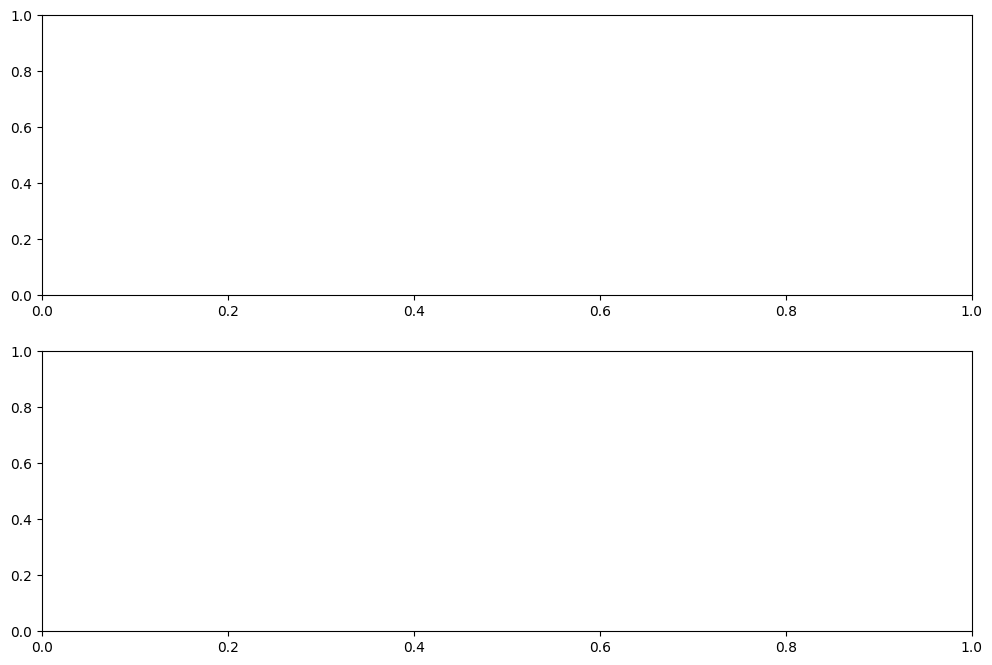

In [ ]:

import librosa.display
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, signal_stft, title in [
    (axes[0], clean_stft, "Clean Speech Spectrogram"),
    (axes[1], noisy_stft, "Noisy Speech Spectrogram (5 dB SNR)")
]:
    magnitude_db = librosa.amplitude_to_db(
        np.abs(signal_stft), ref=np.max
    )

    img = librosa.display.specshow(
        magnitude_db,
        sr=sr_clean,
        hop_length=HOP_LENGTH,
        x_axis="time",
        y_axis="linear",
        ax=ax
    )

    ax.set_title(title)
    fig.colorbar(img, ax=ax, format="%+2.0f dB")

plt.tight_layout()
plt.show()


In [ ]:
# statistical analysis for the same spectograms

In [ ]:

import numpy as np
import pandas as pd

# Magnitude spectrograms
clean_mag = np.abs(clean_stft)
noisy_mag = np.abs(noisy_stft)

# Power spectrograms
clean_power = clean_mag ** 2
noisy_power = noisy_mag ** 2

def describe_spectrogram(name, magnitude, power):
    print(f"\n--- {name} ---")
    print("Shape:", magnitude.shape)
    print("Minimum magnitude:", f"{magnitude.min():.8f}")
    print("Maximum magnitude:", f"{magnitude.max():.8f}")
    print("Mean magnitude:", f"{magnitude.mean():.8f}")
    print("Median magnitude:", f"{np.median(magnitude):.8f}")
    print("Mean power:", f"{power.mean():.10f}")

describe_spectrogram("CLEAN SPEECH", clean_mag, clean_power)
describe_spectrogram("NOISY SPEECH", noisy_mag, noisy_power)

# Compare average power by frequency band
frequencies = librosa.fft_frequencies(sr=sr_clean, n_fft=N_FFT)

bands = [
    ("0–500 Hz", 0, 500),
    ("500–1000 Hz", 500, 1000),
    ("1000–2000 Hz", 1000, 2000),
    ("2000–4000 Hz", 2000, 4000),
    ("4000–8000 Hz", 4000, 8000),
]

print("\n--- FREQUENCY-BAND POWER COMPARISON ---")
print(f"{'Band':<16} {'Clean power':>15} {'Noisy power':>15} {'Difference dB':>15}")

for name, low, high in bands:
    mask = (frequencies >= low) & (frequencies < high)

    clean_band_power = np.mean(clean_power[mask])
    noisy_band_power = np.mean(noisy_power[mask])

    difference_db = 10 * np.log10(
        (noisy_band_power + 1e-20) /
        (clean_band_power + 1e-20)
    )

    print(
        f"{name:<16} "
        f"{clean_band_power:>15.8e} "
        f"{noisy_band_power:>15.8e} "
        f"{difference_db:>14.3f} dB"
    )

# Overall signal comparison
print("\n--- SIGNAL CHECK ---")
print("Clean waveform RMS:", f"{np.sqrt(np.mean(clean**2)):.8f}")
print("Noisy waveform RMS:", f"{np.sqrt(np.mean(noisy**2)):.8f}")
print("Clean waveform peak:", f"{np.max(np.abs(clean)):.8f}")
print("Noisy waveform peak:", f"{np.max(np.abs(noisy)):.8f}")
print("Target SNR:", row["target_snr_db"], "dB")
print("All spectrogram values finite:",
      bool(np.isfinite(clean_mag).all() and np.isfinite(noisy_mag).all()))


NameError: name 'clean_stft' is not defined

In [ ]:

# Recover the added noise from the matched clean/noisy pair.
# This assumes the noisy signal was created by adding noise to clean speech.
clean64 = clean.astype(np.float64)
noisy64 = noisy.astype(np.float64)
estimated_noise = noisy64 - clean64

clean_power_time = np.mean(clean64 ** 2)
noise_power_time = np.mean(estimated_noise ** 2)

measured_snr_db = 10 * np.log10(
    clean_power_time / max(noise_power_time, 1e-20)
)

print("=== MIXTURE VALIDATION ===")
print("Metadata target SNR:", row["target_snr_db"], "dB")
print(f"Measured SNR: {measured_snr_db:.4f} dB")
print(f"Clean mean-square power: {clean_power_time:.10e}")
print(f"Estimated noise mean-square power: {noise_power_time:.10e}")
print(f"Estimated noise RMS: {np.sqrt(noise_power_time):.8f}")
print("Estimated noise is finite:",
      bool(np.isfinite(estimated_noise).all()))
print("Clean and noisy arrays have equal length:",
      len(clean64) == len(noisy64))

# Check the noise contribution across frequency bands.
noise_stft = librosa.stft(
    estimated_noise.astype(np.float32),
    n_fft=N_FFT,
    hop_length=HOP_LENGTH
)
noise_power_spec = np.abs(noise_stft) ** 2

frequencies = librosa.fft_frequencies(sr=sr_clean, n_fft=N_FFT)

print("\n=== BANDWISE CLEAN-TO-NOISE POWER RATIO ===")
print(f"{'Band':<16} {'Clean power':>15} {'Noise power':>15} {'SNR':>12}")

for name, low, high in bands:
    mask = (frequencies >= low) & (frequencies < high)

    cp = np.mean(clean_power[mask])
    npow = np.mean(noise_power_spec[mask])

    band_snr = 10 * np.log10(max(cp, 1e-20) / max(npow, 1e-20))

    print(f"{name:<16} {cp:>15.6e} {npow:>15.6e} {band_snr:>11.3f} dB")


=== MIXTURE VALIDATION ===
Metadata target SNR: 10 dB
Measured SNR: 10.0000 dB
Clean mean-square power: 7.8008830383e-03
Estimated noise mean-square power: 7.8008729831e-04
Estimated noise RMS: 0.02793004
Estimated noise is finite: True
Clean and noisy arrays have equal length: True


NameError: name 'N_FFT' is not defined

In [ ]:
# ideal spectpgram mask

In [ ]:

# Ideal Ratio Mask (IRM) analysis for one clean/noisy pair.
# Uses STFT magnitudes of clean speech and the estimated added noise.

clean_mag = np.abs(clean_stft)
noise_mag = np.abs(noise_stft)

# Common ideal ratio mask definition
eps = 1e-10
ideal_ratio_mask = clean_mag / (clean_mag + noise_mag + eps)

print("=== IDEAL RATIO MASK ANALYSIS ===")
print("Mask shape:", ideal_ratio_mask.shape)
print("Mask minimum:", f"{ideal_ratio_mask.min():.6f}")
print("Mask maximum:", f"{ideal_ratio_mask.max():.6f}")
print("Mask mean:", f"{ideal_ratio_mask.mean():.6f}")
print("Mask median:", f"{np.median(ideal_ratio_mask):.6f}")
print("All mask values finite:",
      bool(np.isfinite(ideal_ratio_mask).all()))

print("\n=== MASK VALUE DISTRIBUTION ===")
for low, high in [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6),
                  (0.6, 0.8), (0.8, 1.0)]:
    count = np.count_nonzero(
        (ideal_ratio_mask >= low) &
        (ideal_ratio_mask < high if high < 1.0 else ideal_ratio_mask <= high)
    )
    print(f"{low:.1f}–{high:.1f}: {count} bins "
          f"({100 * count / ideal_ratio_mask.size:.2f}%)")



In [ ]:

# Intelli-Speech — Session Initialization
from pathlib import Path
import importlib.util
import subprocess
import sys

# Install only packages that are missing
required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "soundfile": "soundfile",
    "librosa": "librosa",
    "matplotlib": "matplotlib",
}

missing = [
    package
    for module, package in required.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing]
    )

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

# Mount Drive if it is not already mounted
from google.colab import drive
drive.mount("/content/drive")

# Project paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Intelli-Speech-data"
)
DATASET_DIR = PROJECT_DIR / "paired_dataset_v3"

assert DATASET_DIR.exists(), (
    f"Dataset not found: {DATASET_DIR}"
)

print("Intelli-Speech environment initialized.")
print("Dataset:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Librosa:", librosa.__version__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Intelli-Speech environment initialized.
Dataset: /content/drive/MyDrive/Intelli-Speech-data/paired_dataset_v3
Dataset exists: True
NumPy: 2.1.3
Pandas: 2.2.3
Librosa: 0.11.0


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa

# Existing dataset — read only
PROJECT_DIR = Path("/content/drive/MyDrive/Intelli-Speech-data")
DATASET_DIR = PROJECT_DIR / "paired_dataset_v3"
CACHE_DIR = PROJECT_DIR / "analysis_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(DATASET_DIR / "metadata.csv")
row = metadata.loc[metadata["target_snr_db"] == 5].iloc[0]

clean_path = DATASET_DIR / row["clean_file"]
noisy_path = DATASET_DIR / row["noisy_file"]

clean, sr_clean = sf.read(clean_path, dtype="float32")
noisy, sr_noisy = sf.read(noisy_path, dtype="float32")

assert sr_clean == sr_noisy == 16000
assert len(clean) == len(noisy)

N_FFT = 512
HOP_LENGTH = 128

clean_stft = librosa.stft(
    clean, n_fft=N_FFT, hop_length=HOP_LENGTH
)
noisy_stft = librosa.stft(
    noisy, n_fft=N_FFT, hop_length=HOP_LENGTH
)

checkpoint = CACHE_DIR / "stft_example.npz"

np.savez_compressed(
    checkpoint,
    clean_stft=clean_stft,
    noisy_stft=noisy_stft,
    clean=clean,
    noisy=noisy,
    sample_rate=np.array(sr_clean),
    n_fft=np.array(N_FFT),
    hop_length=np.array(HOP_LENGTH),
)

print("=== CHECKPOINT SAVED ===")
print("Path:", checkpoint)
print("Clean STFT shape:", clean_stft.shape)
print("Noisy STFT shape:", noisy_stft.shape)
print("Sample rate:", sr_clean)
print("Checkpoint exists:", checkpoint.exists())
print("Checkpoint size (KB):",
      round(checkpoint.stat().st_size / 1024, 2))


=== CHECKPOINT SAVED ===
Path: /content/drive/MyDrive/Intelli-Speech-data/analysis_cache/stft_example.npz
Clean STFT shape: (257, 510)
Noisy STFT shape: (257, 510)
Sample rate: 16000
Checkpoint exists: True
Checkpoint size (KB): 2200.27


In [ ]:

import numpy as np
from pathlib import Path

checkpoint = Path(
    "/content/drive/MyDrive/Intelli-Speech-data/"
    "analysis_cache/stft_example.npz"
)

with np.load(checkpoint) as saved:
    clean_stft = saved["clean_stft"]
    noisy_stft = saved["noisy_stft"]
    clean = saved["clean"]
    noisy = saved["noisy"]
    sr_clean = int(saved["sample_rate"])
    N_FFT = int(saved["n_fft"])
    HOP_LENGTH = int(saved["hop_length"])

print("=== RESTORATION CHECK ===")
print("Checkpoint loaded:", checkpoint.exists())
print("Clean STFT shape:", clean_stft.shape)
print("Noisy STFT shape:", noisy_stft.shape)
print("Clean waveform length:", len(clean))
print("Noisy waveform length:", len(noisy))
print("Sample rate:", sr_clean)
print("All STFT values finite:",
      bool(np.isfinite(clean_stft).all()
           and np.isfinite(noisy_stft).all()))


=== RESTORATION CHECK ===
Checkpoint loaded: True
Clean STFT shape: (257, 510)
Noisy STFT shape: (257, 510)
Clean waveform length: 65216
Noisy waveform length: 65216
Sample rate: 16000
All STFT values finite: True


In [ ]:

from pathlib import Path
import numpy as np

def load_stft_checkpoint():
    path = Path(
        "/content/drive/MyDrive/Intelli-Speech-data/"
        "analysis_cache/stft_example.npz"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"STFT checkpoint not found: {path}"
        )

    with np.load(path) as data:
        return {
            "clean": data["clean"].copy(),
            "noisy": data["noisy"].copy(),
            "clean_stft": data["clean_stft"].copy(),
            "noisy_stft": data["noisy_stft"].copy(),
            "sample_rate": int(data["sample_rate"]),
            "n_fft": int(data["n_fft"]),
            "hop_length": int(data["hop_length"]),
        }

state = load_stft_checkpoint()

clean = state["clean"]
noisy = state["noisy"]
clean_stft = state["clean_stft"]
noisy_stft = state["noisy_stft"]
sr_clean = state["sample_rate"]
N_FFT = state["n_fft"]
HOP_LENGTH = state["hop_length"]

print("Checkpoint restored successfully.")
print("Clean STFT:", clean_stft.shape)
print("Noisy STFT:", noisy_stft.shape)
print("Sample rate:", sr_clean)


Checkpoint restored successfully.
Clean STFT: (257, 510)
Noisy STFT: (257, 510)
Sample rate: 16000
